In [ ]:
!pip install faiss-cpu

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 23.3 MB/s  0:00:00


In [ ]:
!pip install whoosh

In [ ]:
from pathlib import Path
import json

EVAL_DIR=Path("/content/drive/MyDrive/legal_rag/evaluation")

with open(EVAL_DIR/"labeling_data.json","r",encoding="utf-8") as f:
    labeling_data=json.load(f)

print("Loaded:",len(labeling_data),"queries")

Loaded: 90 queries


In [ ]:
import json
import numpy as np
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt
import faiss
from pathlib import Path
from sklearn.metrics import precision_score,recall_score,f1_score,confusion_matrix
import whoosh
import sys

In [ ]:
sys.path.append("/content/drive/MyDrive/legal_rag/code/")

In [ ]:
import influence_score

In [ ]:
import importlib
import influence_score

importlib.reload(influence_score)

<module 'influence_score' from '/content/drive/MyDrive/legal_rag/code/influence_score.py'>

In [ ]:
VECTOR_DIR=Path("/content/drive/MyDrive/legal_rag/vector_store")
METADATA_FILE=VECTOR_DIR/"metadata.jsonl"
FAISS_FILE=VECTOR_DIR/"legal_cases.index"
BM25_DIR = "/content/drive/MyDrive/legal_rag/vector_store/bm25_index"
CITATION_COUNTS_PATH=Path("/content/drive/MyDrive/legal_rag/cache/citation_counts.json")

MODEL_NAME="sentence-transformers/all-MiniLM-L6-v2"

FINAL_TOP_K=30

In [ ]:
print("Loading FAISS...")
faiss_index=influence_score.load_faiss()

print("Loading BM25...")
bm25_idx=influence_score.load_bm25()

print("Loading embedding model...")
embed_model=influence_score.load_model()

print("Loading citation counts...")
citation_counts=influence_score.load_saved_citation_counts()

print("FAISS:",faiss_index.ntotal)
print("BM25:",bm25_idx.doc_count())
print("Citation entries:",len(citation_counts))

Loading FAISS...
Loading BM25...
Loading embedding model...
Loading embedding model (sentence-transformers/all-MiniLM-L6-v2) on cpu...


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (5 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Loading citation counts...
Loading citation counts...
Citation counts loaded: 200,479 entries
FAISS: 689259
BM25: 689259
Citation entries: 200479


In [ ]:
evaluation_queries=[
    # =========================
    # AUSTRALIA
    # =========================

    {
        "query_id":"AUS_001",
        "query":"What is the legal test for negligence?",
        "jurisdiction":"Australia"
    },
    {
        "query_id":"AUS_002",
        "query":"What are the elements required to establish negligence?",
        "jurisdiction":"Australia"
    },
    {
        "query_id":"AUS_003",
        "query":"When does a duty of care arise?",
        "jurisdiction":"Australia"
    },
    {
        "query_id":"AUS_004",
        "query":"When can a defendant be held liable for breach of duty of care?",
        "jurisdiction":"Australia"
    },
    {
        "query_id":"AUS_005",
        "query":"How is causation determined in negligence cases?",
        "jurisdiction":"Australia"
    },
    {
        "query_id":"AUS_006",
        "query":"What is the test for remoteness of damage in negligence?",
        "jurisdiction":"Australia"
    },
    {
        "query_id":"AUS_007",
        "query":"What factors determine whether a duty of care exists?",
        "jurisdiction":"Australia"
    },
    {
        "query_id":"AUS_008",
        "query":"What is the standard of care expected of a reasonable person?",
        "jurisdiction":"Australia"
    },
    {
        "query_id":"AUS_009",
        "query":"When can contributory negligence reduce damages?",
        "jurisdiction":"Australia"
    },
    {
        "query_id":"AUS_010",
        "query":"When can a court depart from an earlier precedent?",
        "jurisdiction":"Australia"
    },
    {
        "query_id":"AUS_011",
        "query":"What principles govern the doctrine of precedent?",
        "jurisdiction":"Australia"
    },
    {
        "query_id":"AUS_012",
        "query":"When is a lower court bound by a decision of a higher court?",
        "jurisdiction":"Australia"
    },
    {
        "query_id":"AUS_013",
        "query":"What is the distinction between ratio decidendi and obiter dicta?",
        "jurisdiction":"Australia"
    },
    {
        "query_id":"AUS_014",
        "query":"How should conflicting judicial authorities be resolved?",
        "jurisdiction":"Australia"
    },
    {
        "query_id":"AUS_015",
        "query":"When can a court overrule its previous decision?",
        "jurisdiction":"Australia"
    },
    {
        "query_id":"AUS_016",
        "query":"How should statutory provisions be interpreted?",
        "jurisdiction":"Australia"
    },
    {
        "query_id":"AUS_017",
        "query":"What is the role of statutory purpose in interpreting legislation?",
        "jurisdiction":"Australia"
    },
    {
        "query_id":"AUS_018",
        "query":"How does the court determine the meaning of ambiguous statutory language?",
        "jurisdiction":"Australia"
    },
    {
        "query_id":"AUS_019",
        "query":"When can extrinsic materials be considered in statutory interpretation?",
        "jurisdiction":"Australia"
    },
    {
        "query_id":"AUS_020",
        "query":"What principles apply when interpreting legislation in its statutory context?",
        "jurisdiction":"Australia"
    },
    {
        "query_id":"AUS_021",
        "query":"What factors are relevant when determining whether a contract has been breached?",
        "jurisdiction":"Australia"
    },
    {
        "query_id":"AUS_022",
        "query":"How is contractual intention determined?",
        "jurisdiction":"Australia"
    },
    {
        "query_id":"AUS_023",
        "query":"When can a contractual term be considered a condition?",
        "jurisdiction":"Australia"
    },
    {
        "query_id":"AUS_024",
        "query":"When can damages be awarded for breach of contract?",
        "jurisdiction":"Australia"
    },
    {
        "query_id":"AUS_025",
        "query":"What is required to establish unconscionable conduct?",
        "jurisdiction":"Australia"
    },
    {
        "query_id":"AUS_026",
        "query":"What principles govern procedural fairness?",
        "jurisdiction":"Australia"
    },
    {
        "query_id":"AUS_027",
        "query":"When does procedural fairness require a hearing?",
        "jurisdiction":"Australia"
    },
    {
        "query_id":"AUS_028",
        "query":"What circumstances can justify judicial review of administrative action?",
        "jurisdiction":"Australia"
    },
    {
        "query_id":"AUS_029",
        "query":"What is the scope of judicial review of administrative decisions?",
        "jurisdiction":"Australia"
    },
    {
        "query_id":"AUS_030",
        "query":"What remedies are available following a finding of unlawful administrative action?",
        "jurisdiction":"Australia"
    },

    # =========================
    # SINGAPORE
    # =========================

    {
        "query_id":"SG_001",
        "query":"What is the legal test for negligence?",
        "jurisdiction":"Singapore"
    },
    {
        "query_id":"SG_002",
        "query":"What are the elements required to establish negligence?",
        "jurisdiction":"Singapore"
    },
    {
        "query_id":"SG_003",
        "query":"When does a duty of care arise?",
        "jurisdiction":"Singapore"
    },
    {
        "query_id":"SG_004",
        "query":"When can a defendant be held liable for breach of duty of care?",
        "jurisdiction":"Singapore"
    },
    {
        "query_id":"SG_005",
        "query":"How is causation determined in negligence cases?",
        "jurisdiction":"Singapore"
    },
    {
        "query_id":"SG_006",
        "query":"What is the test for remoteness of damage in negligence?",
        "jurisdiction":"Singapore"
    },
    {
        "query_id":"SG_007",
        "query":"What factors determine whether a duty of care exists?",
        "jurisdiction":"Singapore"
    },
    {
        "query_id":"SG_008",
        "query":"What is the standard of care expected of a reasonable person?",
        "jurisdiction":"Singapore"
    },
    {
        "query_id":"SG_009",
        "query":"When can contributory negligence reduce damages?",
        "jurisdiction":"Singapore"
    },
    {
        "query_id":"SG_010",
        "query":"When can a court depart from an earlier precedent?",
        "jurisdiction":"Singapore"
    },
    {
        "query_id":"SG_011",
        "query":"What principles govern the doctrine of precedent?",
        "jurisdiction":"Singapore"
    },
    {
        "query_id":"SG_012",
        "query":"When is a lower court bound by a decision of a higher court?",
        "jurisdiction":"Singapore"
    },
    {
        "query_id":"SG_013",
        "query":"What is the distinction between ratio decidendi and obiter dicta?",
        "jurisdiction":"Singapore"
    },
    {
        "query_id":"SG_014",
        "query":"How should conflicting judicial authorities be resolved?",
        "jurisdiction":"Singapore"
    },
    {
        "query_id":"SG_015",
        "query":"When can a court overrule its previous decision?",
        "jurisdiction":"Singapore"
    },
    {
        "query_id":"SG_016",
        "query":"How should statutory provisions be interpreted?",
        "jurisdiction":"Singapore"
    },
    {
        "query_id":"SG_017",
        "query":"What is the role of statutory purpose in interpreting legislation?",
        "jurisdiction":"Singapore"
    },
    {
        "query_id":"SG_018",
        "query":"How does the court determine the meaning of ambiguous statutory language?",
        "jurisdiction":"Singapore"
    },
    {
        "query_id":"SG_019",
        "query":"When can extrinsic materials be considered in statutory interpretation?",
        "jurisdiction":"Singapore"
    },
    {
        "query_id":"SG_020",
        "query":"What principles apply when interpreting legislation in its statutory context?",
        "jurisdiction":"Singapore"
    },
    {
        "query_id":"SG_021",
        "query":"What factors are relevant when determining whether a contract has been breached?",
        "jurisdiction":"Singapore"
    },
    {
        "query_id":"SG_022",
        "query":"How is contractual intention determined?",
        "jurisdiction":"Singapore"
    },
    {
        "query_id":"SG_023",
        "query":"When can a contractual term be considered a condition?",
        "jurisdiction":"Singapore"
    },
    {
        "query_id":"SG_024",
        "query":"When can damages be awarded for breach of contract?",
        "jurisdiction":"Singapore"
    },
    {
        "query_id":"SG_025",
        "query":"What is required to establish unconscionable conduct?",
        "jurisdiction":"Singapore"
    },
    {
        "query_id":"SG_026",
        "query":"What principles govern procedural fairness?",
        "jurisdiction":"Singapore"
    },
    {
        "query_id":"SG_027",
        "query":"When does procedural fairness require a hearing?",
        "jurisdiction":"Singapore"
    },
    {
        "query_id":"SG_028",
        "query":"What circumstances can justify judicial review of administrative action?",
        "jurisdiction":"Singapore"
    },
    {
        "query_id":"SG_029",
        "query":"What is the scope of judicial review of administrative decisions?",
        "jurisdiction":"Singapore"
    },
    {
        "query_id":"SG_030",
        "query":"What remedies are available following a finding of unlawful administrative action?",
        "jurisdiction":"Singapore"
    },

    # =========================
    # USA - SOUTH CAROLINA
    # =========================

    {
        "query_id":"USA_001",
        "query":"What is the legal test for negligence?",
        "jurisdiction":"USA - South Carolina"
    },
    {
        "query_id":"USA_002",
        "query":"What are the elements required to establish negligence?",
        "jurisdiction":"USA - South Carolina"
    },
    {
        "query_id":"USA_003",
        "query":"When does a duty of care arise?",
        "jurisdiction":"USA - South Carolina"
    },
    {
        "query_id":"USA_004",
        "query":"When can a defendant be held liable for breach of duty of care?",
        "jurisdiction":"USA - South Carolina"
    },
    {
        "query_id":"USA_005",
        "query":"How is causation determined in negligence cases?",
        "jurisdiction":"USA - South Carolina"
    },
    {
        "query_id":"USA_006",
        "query":"What is the test for remoteness of damage in negligence?",
        "jurisdiction":"USA - South Carolina"
    },
    {
        "query_id":"USA_007",
        "query":"What factors determine whether a duty of care exists?",
        "jurisdiction":"USA - South Carolina"
    },
    {
        "query_id":"USA_008",
        "query":"What is the standard of care expected of a reasonable person?",
        "jurisdiction":"USA - South Carolina"
    },
    {
        "query_id":"USA_009",
        "query":"When can contributory negligence reduce damages?",
        "jurisdiction":"USA - South Carolina"
    },
    {
        "query_id":"USA_010",
        "query":"When can a court depart from an earlier precedent?",
        "jurisdiction":"USA - South Carolina"
    },
    {
        "query_id":"USA_011",
        "query":"What principles govern the doctrine of precedent?",
        "jurisdiction":"USA - South Carolina"
    },
    {
        "query_id":"USA_012",
        "query":"When is a lower court bound by a decision of a higher court?",
        "jurisdiction":"USA - South Carolina"
    },
    {
        "query_id":"USA_013",
        "query":"What is the distinction between ratio decidendi and obiter dicta?",
        "jurisdiction":"USA - South Carolina"
    },
    {
        "query_id":"USA_014",
        "query":"How should conflicting judicial authorities be resolved?",
        "jurisdiction":"USA - South Carolina"
    },
    {
        "query_id":"USA_015",
        "query":"When can a court overrule its previous decision?",
        "jurisdiction":"USA - South Carolina"
    },
    {
        "query_id":"USA_016",
        "query":"How should statutory provisions be interpreted?",
        "jurisdiction":"USA - South Carolina"
    },
    {
        "query_id":"USA_017",
        "query":"What is the role of statutory purpose in interpreting legislation?",
        "jurisdiction":"USA - South Carolina"
    },
    {
        "query_id":"USA_018",
        "query":"How does the court determine the meaning of ambiguous statutory language?",
        "jurisdiction":"USA - South Carolina"
    },
    {
        "query_id":"USA_019",
        "query":"When can extrinsic materials be considered in statutory interpretation?",
        "jurisdiction":"USA - South Carolina"
    },
    {
        "query_id":"USA_020",
        "query":"What principles apply when interpreting legislation in its statutory context?",
        "jurisdiction":"USA - South Carolina"
    },
    {
        "query_id":"USA_021",
        "query":"What factors are relevant when determining whether a contract has been breached?",
        "jurisdiction":"USA - South Carolina"
    },
    {
        "query_id":"USA_022",
        "query":"How is contractual intention determined?",
        "jurisdiction":"USA - South Carolina"
    },
    {
        "query_id":"USA_023",
        "query":"When can a contractual term be considered a condition?",
        "jurisdiction":"USA - South Carolina"
    },
    {
        "query_id":"USA_024",
        "query":"When can damages be awarded for breach of contract?",
        "jurisdiction":"USA - South Carolina"
    },
    {
        "query_id":"USA_025",
        "query":"What is required to establish unconscionable conduct?",
        "jurisdiction":"USA - South Carolina"
    },
    {
        "query_id":"USA_026",
        "query":"What principles govern procedural fairness?",
        "jurisdiction":"USA - South Carolina"
    },
    {
        "query_id":"USA_027",
        "query":"When does procedural fairness require a hearing?",
        "jurisdiction":"USA - South Carolina"
    },
    {
        "query_id":"USA_028",
        "query":"What circumstances can justify judicial review of administrative action?",
        "jurisdiction":"USA - South Carolina"
    },
    {
        "query_id":"USA_029",
        "query":"What is the scope of judicial review of administrative decisions?",
        "jurisdiction":"USA - South Carolina"
    },
    {
        "query_id":"USA_030",
        "query":"What remedies are available following a finding of unlawful administrative action?",
        "jurisdiction":"USA - South Carolina"
    }
]

In [ ]:
queries = {
    "AUS_J01": {
        "jurisdiction": "Australia",
        "query": "How did the High Court of Australia establish the recognition of native title in Mabo v Queensland (No 2), and how have subsequent judgments applied its principles?"
    },
    "AUS_J02": {
        "jurisdiction": "Australia",
        "query": "How has the High Court of Australia developed the implied freedom of political communication through its judgments, and what test does it apply to laws that burden this freedom?"
    },
    "AUS_J03": {
        "jurisdiction": "Australia",
        "query": "How has the High Court of Australia interpreted the constitutional requirement that members of Parliament be directly chosen by the people?"
    },
    "AUS_J04": {
        "jurisdiction": "Australia",
        "query": "How has the High Court of Australia interpreted the scope of Commonwealth legislative power in disputes concerning the relationship between Commonwealth and State laws?"
    },
    "AUS_J05": {
        "jurisdiction": "Australia",
        "query": "How has the High Court of Australia addressed the limits of judicial review when determining whether an administrative decision-maker has exceeded their legal authority?"
    },

    "SG_J01": {
        "jurisdiction": "Singapore",
        "query": "How did Spandeck Engineering (S) Pte Ltd v Defence Science & Technology Agency establish the test for determining whether a duty of care exists under Singapore law?"
    },
    "SG_J02": {
        "jurisdiction": "Singapore",
        "query": "How have subsequent Singapore Court of Appeal judgments applied the Spandeck test to claims involving pure economic loss?"
    },
    "SG_J03": {
        "jurisdiction": "Singapore",
        "query": "How did the Court of Appeal in Tan Cheng Bock v Attorney-General approach the interpretation of constitutional provisions?"
    },
    "SG_J04": {
        "jurisdiction": "Singapore",
        "query": "How have Singapore courts interpreted statutory provisions by considering their text, context, and legislative purpose?"
    },
    "SG_J05": {
        "jurisdiction": "Singapore",
        "query": "How have Singapore courts determined whether a public authority's exercise of statutory power is subject to judicial review?"
    },

    "USA_SC_J01": {
        "jurisdiction": "USA - South Carolina",
        "query": "How did Nelson v. Concrete Supply Co. change South Carolina's approach to contributory negligence and comparative negligence?"
    },
    "USA_SC_J02": {
        "jurisdiction": "USA - South Carolina",
        "query": "How have subsequent South Carolina Supreme Court decisions applied the comparative negligence principles established in Nelson v. Concrete Supply Co.?"
    },
    "USA_SC_J03": {
        "jurisdiction": "USA - South Carolina",
        "query": "How did Mickle v. Blackmon influence the development of products liability law in South Carolina?"
    },
    "USA_SC_J04": {
        "jurisdiction": "USA - South Carolina",
        "query": "How have South Carolina courts applied the Tyger River doctrine in insurance bad-faith claims involving a refusal to settle within policy limits?"
    },
    "USA_SC_J05": {
        "jurisdiction": "USA - South Carolina",
        "query": "How has the South Carolina Supreme Court interpreted the constitutionality of statutory provisions governing criminal sentencing?"
    }
}

import json

output_path = "/content/drive/MyDrive/legal_rag/evaluation/jurisdiction_specific_queries.json"

with open(output_path, "w", encoding="utf-8") as f:
    json.dump(queries, f, indent=4, ensure_ascii=False)

print(f"Saved {len(queries)} queries to {output_path}")

Saved 15 queries to /content/drive/MyDrive/legal_rag/evaluation/jurisdiction_specific_queries.json


In [ ]:
EVAL_DIR=Path("/content/drive/MyDrive/legal_rag/evaluation")
EVAL_DIR.mkdir(parents=True,exist_ok=True)

with open(EVAL_DIR/"evaluation_queries.json","w",encoding="utf-8") as f:
    json.dump(evaluation_queries,f,indent=2)

print("Saved:",EVAL_DIR/"evaluation_queries.json")
print("Total queries:",len(evaluation_queries))

In [ ]:
labeling_data=[]
with open(EVAL_DIR/"evaluation_queries.json","r",encoding="utf-8") as f:
    evaluation_queries=json.load(f)
for i,q in enumerate(evaluation_queries,1):
    print(f"{i}/{len(evaluation_queries)}: {q['query_id']}")

    candidates=get_label_candidates(
        q["query"],
        q["jurisdiction"],
        top_k=30
    )

    cases=[]

    for c in candidates:
        cases.append({
            "case_id":c["case_id"],
            "case_name":c.get("case_name",""),
            "citation":c.get("citation",""),
            "court":c.get("court",""),
            "jurisdiction":c.get("jurisdiction",""),
            "text":c.get("text",""),
            "relevance":None
        })

    labeling_data.append({
        "query_id":q["query_id"],
        "query":q["query"],
        "jurisdiction":q["jurisdiction"],
        "cases":cases
    })

with open(EVAL_DIR/"labeling_data.json","w",encoding="utf-8") as f:
    json.dump(labeling_data,f,indent=2,ensure_ascii=False)

print("\nSaved labeling file.")

1/90: AUS_001
FAISS results (Australia): 50
BM25 results after Australia filter: 1
2/90: AUS_002
FAISS results (Australia): 50
BM25 results after Australia filter: 1
3/90: AUS_003
FAISS results (Australia): 50
BM25 results after Australia filter: 0
4/90: AUS_004
FAISS results (Australia): 50
BM25 results after Australia filter: 0
5/90: AUS_005
FAISS results (Australia): 50
BM25 results after Australia filter: 4
6/90: AUS_006
FAISS results (Australia): 50
BM25 results after Australia filter: 1
7/90: AUS_007
FAISS results (Australia): 50
BM25 results after Australia filter: 3
8/90: AUS_008
FAISS results (Australia): 50
BM25 results after Australia filter: 2
9/90: AUS_009
FAISS results (Australia): 50
BM25 results after Australia filter: 6
10/90: AUS_010
FAISS results (Australia): 50
BM25 results after Australia filter: 1
11/90: AUS_011
FAISS results (Australia): 50
BM25 results after Australia filter: 3
12/90: AUS_012
FAISS results (Australia): 50
BM25 results after Australia filter: 0
1

In [ ]:
import json,random

METADATA_FILE="/content/drive/MyDrive/legal_rag/vector_store/metadata2.jsonl"
RANDOM_CASES_PER_QUERY=10

def get_case_texts(case_ids):
    case_ids=set(case_ids)
    results={}

    with open(METADATA_FILE,"r",encoding="utf-8") as f:
        for line in f:
            data=json.loads(line)
            case_id=data.get("case_id")

            if case_id in case_ids:
                results.setdefault(case_id,[]).append(data.get("text",""))

                if len(results)==len(case_ids):
                    break

    return {
        case_id:"\n".join(texts)
        for case_id,texts in results.items()
    }

print("Functions loaded.")

Functions loaded.


In [ ]:
def get_random_cases(jurisdiction,excluded_ids,n=10):
    reservoir=[]
    seen=set()

    with open(METADATA_FILE,"r",encoding="utf-8") as f:
        for line in f:
            data=json.loads(line)

            if data.get("jurisdiction")!=jurisdiction:
                continue

            case_id=data.get("case_id")

            if case_id in excluded_ids or case_id in seen:
                continue

            seen.add(case_id)

            if len(reservoir)<n:
                reservoir.append(data)
            else:
                j=random.randint(0,len(seen)-1)
                if j<n:
                    reservoir[j]=data

    return reservoir

In [ ]:
evaluation_pools=[]
EVAL_DIR=Path("/content/drive/MyDrive/legal_rag/evaluation")
for qi,q in enumerate(labeling_data):
    jurisdiction=q["jurisdiction"]
    retrieved_ids={c["case_id"] for c in q["cases"]}

    text_lookup=get_case_texts(retrieved_ids)

    retrieved_cases=[]

    for c in q["cases"]:
        item=dict(c)
        item["text"]=text_lookup.get(c["case_id"],"")
        retrieved_cases.append(item)

    random_cases=get_random_cases(
        jurisdiction,
        retrieved_ids,
        RANDOM_CASES_PER_QUERY
    )

    evaluation_pools.append({
        "query_id":q["query_id"],
        "query":q["query"],
        "jurisdiction":jurisdiction,
        "retrieved_cases":retrieved_cases,
        "random_cases":random_cases
    })

    if (qi+1)%10==0:
        print(f"Processed {qi+1}/90 queries")
        if (qi+1==90):
          with open(EVAL_DIR/"evaluation_pools.json","w",encoding="utf-8") as f:
            json.dump(evaluation_pools,f,indent=2,ensure_ascii=False)


Processed 10/90 queries
Processed 20/90 queries
Processed 30/90 queries
Processed 40/90 queries
Processed 50/90 queries
Processed 60/90 queries
Processed 70/90 queries
Processed 80/90 queries
Processed 90/90 queries


In [ ]:
!pip install -q -U transformers accelerate bitsandbytes

In [ ]:
import torch
import torch.nn.functional as F

In [ ]:
from sentence_transformers import SentenceTransformer

EMBED_MODEL_NAME="sentence-transformers/all-MiniLM-L6-v2"
EMBED_MODEL_PATH="/content/drive/MyDrive/legal_rag/models/all-MiniLM-L6-v2"

embedding_model=SentenceTransformer(EMBED_MODEL_NAME)
embedding_model.save(EMBED_MODEL_PATH)

print("Embedding model saved to:")
print(EMBED_MODEL_PATH)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Embedding model saved to:
/content/drive/MyDrive/legal_rag/models/all-MiniLM-L6-v2


In [ ]:
from sentence_transformers import SentenceTransformer

EMBED_MODEL_PATH="/content/drive/MyDrive/legal_rag/models/all-MiniLM-L6-v2"

embedding_model=SentenceTransformer(EMBED_MODEL_PATH)

print("Embedding model loaded.")
print(embedding_model.encode(["test query"]).shape)

Loading weights:   0%|          | 0/103 [00:01<?, ?it/s]

Embedding model loaded.
(1, 384)


In [ ]:
EVAL_DIR=Path("/content/drive/MyDrive/legal_rag/evaluation")
with open(EVAL_DIR/"evaluation_queries_final.json","r",encoding="utf-8") as f:
  evaluation_pools=json.load(f)

In [ ]:
!pip install -q sentence-transformers

In [ ]:
from sentence_transformers import CrossEncoder

RERANKER_NAME="cross-encoder/ms-marco-MiniLM-L-6-v2"

reranker=CrossEncoder(
    RERANKER_NAME,
    max_length=512
)

print("Reranker loaded.")

config.json:   0%|          | 0.00/794 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/1.33k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/132 [00:00<?, ?B/s]

Reranker loaded.


In [ ]:
import numpy as np
import torch

def get_relevant_passages(query,case_text,embedding_model,top_n=3,passage_size=1200):
    if not case_text or not case_text.strip():
        return []

    words=case_text.split()
    passages=[]

    for i in range(0,len(words),passage_size):
        passage=" ".join(words[i:i+passage_size])
        if passage.strip():
            passages.append(passage)

    if not passages:
        return []

    query_embedding=embedding_model.encode(
        [query],
        normalize_embeddings=True
    )[0]

    passage_embeddings=embedding_model.encode(
        passages,
        normalize_embeddings=True,
        batch_size=32,
        show_progress_bar=False
    )

    scores=np.dot(passage_embeddings,query_embedding)
    top_indices=np.argsort(scores)[::-1][:top_n]

    return [passages[i] for i in top_indices]

In [ ]:
import numpy as np
import json
from pathlib import Path

reranker_scores=[]

for qi,q in enumerate(evaluation_pools):
    print(f"Processing {qi+1}/{len(evaluation_pools)}: {q['query_id']}")

    cases=[]

    for c in q["retrieved_cases"]:
        item=dict(c)
        item["source"]="retrieved"
        cases.append(item)

    for c in q["random_cases"]:
        item=dict(c)
        item["source"]="random"
        cases.append(item)

    pairs=[]
    valid_cases=[]

    for c in cases:
        passages=get_relevant_passages(
            q["query"],
            c["text"],
            embedding_model,
            top_n=3
        )

        if not passages:
            continue

        evidence="\n".join(passages)
        pairs.append([q["query"],evidence])
        valid_cases.append(c)

    scores_q=reranker.predict(
        pairs,
        batch_size=8,
        show_progress_bar=False
    )

    for c,score in zip(valid_cases,scores_q):
        reranker_scores.append({
            "query_id":q["query_id"],
            "jurisdiction":q["jurisdiction"],
            "case_id":c["case_id"],
            "case_name":c["case_name"],
            "source":c["source"],
            "score":float(score)
        })

print("\nTotal scored:",len(reranker_scores))
with open(EVAL_DIR/"reranker_scores.json","w",encoding="utf-8") as f:
    json.dump(reranker_scores,f,indent=2,ensure_ascii=False)

Processing 1/90: AUS_001
Processing 2/90: AUS_002
Processing 3/90: AUS_003
Processing 4/90: AUS_004
Processing 5/90: AUS_005
Processing 6/90: AUS_006
Processing 7/90: AUS_007
Processing 8/90: AUS_008
Processing 9/90: AUS_009
Processing 10/90: AUS_010
Processing 11/90: AUS_011
Processing 12/90: AUS_012
Processing 13/90: AUS_013
Processing 14/90: AUS_014
Processing 15/90: AUS_015
Processing 16/90: AUS_016
Processing 17/90: AUS_017
Processing 18/90: AUS_018
Processing 19/90: AUS_019
Processing 20/90: AUS_020
Processing 21/90: AUS_021
Processing 22/90: AUS_022
Processing 23/90: AUS_023
Processing 24/90: AUS_024
Processing 25/90: AUS_025
Processing 26/90: AUS_026
Processing 27/90: AUS_027
Processing 28/90: AUS_028
Processing 29/90: AUS_029
Processing 30/90: AUS_030
Processing 31/90: SG_001
Processing 32/90: SG_002
Processing 33/90: SG_003
Processing 34/90: SG_004
Processing 35/90: SG_005
Processing 36/90: SG_006
Processing 37/90: SG_007
Processing 38/90: SG_008
Processing 39/90: SG_009
Proc

In [ ]:
EVAL_DIR=Path("/content/drive/MyDrive/legal_rag/evaluation")
with open(EVAL_DIR/"reranker_scores.json","r",encoding="utf-8") as f:
  reranker_scores=json.load(f)

In [ ]:
from collections import defaultdict
import numpy as np

by_group=defaultdict(list)
by_jurisdiction=defaultdict(lambda:defaultdict(list))

for x in reranker_scores:
    by_group[x["source"]].append(x["score"])
    by_jurisdiction[x["jurisdiction"]][x["source"]].append(x["score"])

print("OVERALL")

for source,s in by_group.items():
    print(
        source,
        "| n =",len(s),
        "| mean =",round(np.mean(s),4),
        "| median =",round(np.median(s),4),
        "| min =",round(min(s),4),
        "| max =",round(max(s),4)
    )

print("\nBY JURISDICTION")

for jurisdiction,groups in by_jurisdiction.items():
    print("\n",jurisdiction)

    for source,s in groups.items():
        print(
            source,
            "| n =",len(s),
            "| mean =",round(np.mean(s),4),
            "| median =",round(np.median(s),4),
            "| min =",round(min(s),4),
            "| max =",round(max(s),4)
        )

OVERALL
retrieved | n = 2554 | mean = -6.8761 | median = -7.6824 | min = -11.4603 | max = 5.8373
random | n = 900 | mean = -10.8888 | median = -11.1772 | min = -11.5034 | max = -2.7967

BY JURISDICTION

 Australia
retrieved | n = 848 | mean = -6.9316 | median = -7.9123 | min = -11.4464 | max = 4.7874
random | n = 300 | mean = -10.7994 | median = -11.1729 | min = -11.4689 | max = -2.7967

 Singapore
retrieved | n = 846 | mean = -7.1061 | median = -8.1599 | min = -11.4603 | max = 5.8373
random | n = 300 | mean = -11.0294 | median = -11.2467 | min = -11.5034 | max = -4.9483

 USA - South Carolina
retrieved | n = 860 | mean = -6.5952 | median = -7.1059 | min = -11.4072 | max = 3.0972
random | n = 300 | mean = -10.8376 | median = -11.128 | min = -11.4655 | max = -2.8971


In [ ]:
mport numpy as np

def assign_grade(group):

    q25 = group["score"].quantile(0.25)
    q50 = group["score"].quantile(0.50)
    q75 = group["score"].quantile(0.75)

    def grade(score):
        if score >= q75:
            return 3
        elif score >= q50:
            return 2
        elif score >= q25:
            return 1
        else:
            return 0

    group["relevance_grade"] = group["score"].apply(grade)

    return group

scores_df = (
    scores_df
    .groupby("query_id", group_keys=False)
    .apply(assign_grade)
    .reset_index(drop=True)
)

NameError: name 'scores_df' is not defined

In [ ]:
print(
    scores_df[
        [
            "query_id",
            "case_id",
            "source",
            "score",
            "relevance_grade"
        ]
    ].head(20)
)

   query_id                            case_id     source     score  \
0   AUS_001                          S259/2009  retrieved -1.610174   
1   AUS_001                           M43/1998  retrieved  4.787365   
2   AUS_001                           H12/2015  retrieved -0.444014   
3   AUS_001                           A14/2015  retrieved -2.322531   
4   AUS_001                          S631/2003  retrieved -1.576113   
5   AUS_001                           P31/2010  retrieved -1.653353   
6   AUS_001                           A36/2005  retrieved -4.163505   
7   AUS_001                          S108/2002  retrieved -0.133219   
8   AUS_001                           S47/2008  retrieved -4.155123   
9   AUS_001  S122/2002 & S125/2002 & S126/2002  retrieved -0.611654   
10  AUS_001                          S122/2007  retrieved -3.640156   
11  AUS_001                           M61/2003  retrieved -3.025759   
12  AUS_001                            H3/2005  retrieved -2.770696   
13  AU

In [ ]:
with open("/content/drive/MyDrive/legal_rag/evaluation/evaluation_queries_final.json","r",encoding="utf-8") as f:
    evaluation_queries=json.load(f)

In [ ]:
import os
import shutil

BM25_DIR = "/content/drive/MyDrive/legal_rag/vector_store/bm25_index"
BM25_BACKUP = "/content/drive/MyDrive/legal_rag/vector_store/bm25_index_backup"

if os.path.exists(BM25_DIR) and not os.path.exists(BM25_BACKUP):
    shutil.copytree(BM25_DIR, BM25_BACKUP)
    print("Backup created:", BM25_BACKUP)
else:
    print("Backup already exists or BM25 index not found.")

Backup created: /content/drive/MyDrive/legal_rag/vector_store/bm25_index_backup


In [ ]:
import os
import shutil

LOCAL_BM25 = "/content/bm25_index"
DRIVE_BM25 = "/content/drive/MyDrive/legal_rag/vector_store/bm25_index"

if os.path.exists(LOCAL_BM25):
    shutil.rmtree(LOCAL_BM25)

if os.path.exists(DRIVE_BM25):
    shutil.rmtree(DRIVE_BM25)

print("Old BM25 indexes removed.")

Old BM25 indexes removed.


In [ ]:
import os
import json
import shutil
import time

from whoosh import index
from whoosh.fields import Schema, TEXT, ID

METADATA_FILE = "/content/drive/MyDrive/legal_rag/vector_store/metadata.jsonl"

LOCAL_BM25 = "/content/bm25_index"

if os.path.exists(LOCAL_BM25):
    shutil.rmtree(LOCAL_BM25)

os.makedirs(LOCAL_BM25, exist_ok=True)

schema = Schema(
    chunk_id=ID(stored=True, unique=True),
    jurisdiction=ID(stored=True),
    text=TEXT(stored=False)
)

ix = index.create_in(
    LOCAL_BM25,
    schema
)

writer = ix.writer(
    limitmb=128,
    procs=1,
    multisegment=True
)

count = 0
skipped = 0

start_time = time.time()

with open(METADATA_FILE, "r", encoding="utf-8") as f:

    for line in f:

        line = line.strip()

        if not line:
            continue

        try:
            item = json.loads(line)

            chunk_id = item.get("chunk_id")
            text = item.get("text")
            jurisdiction = item.get("jurisdiction")

            if not chunk_id or not text or not jurisdiction:
                skipped += 1
                continue

            writer.add_document(
                chunk_id=str(chunk_id),
                jurisdiction=str(jurisdiction),
                text=str(text)
            )

            count += 1

            if count % 10000 == 0:

                elapsed = time.time() - start_time

                print(
                    f"Indexed {count:,} chunks | "
                    f"{elapsed/60:.1f} min"
                )

        except Exception as e:
            skipped += 1

            if skipped <= 10:
                print("Skipped:", e)

print("\nFinished adding documents.")
print("Total:", count)
print("Skipped:", skipped)

print("\nCommitting Whoosh index...")
writer.commit()

print("Commit complete.")

print("\nLocal BM25 size:")

total_size = 0

for root, dirs, files in os.walk(LOCAL_BM25):
    for file in files:
        path = os.path.join(root, file)
        total_size += os.path.getsize(path)

print(f"{total_size / (1024**3):.2f} GB")

Indexed 10,000 chunks | 0.3 min
Indexed 20,000 chunks | 0.7 min
Indexed 30,000 chunks | 0.9 min
Indexed 40,000 chunks | 1.2 min
Indexed 50,000 chunks | 1.4 min
Indexed 60,000 chunks | 1.6 min
Indexed 70,000 chunks | 1.9 min
Indexed 80,000 chunks | 2.1 min
Indexed 90,000 chunks | 2.4 min
Indexed 100,000 chunks | 2.6 min
Indexed 110,000 chunks | 2.9 min
Indexed 120,000 chunks | 3.2 min
Indexed 130,000 chunks | 3.5 min
Indexed 140,000 chunks | 3.7 min
Indexed 150,000 chunks | 3.9 min
Indexed 160,000 chunks | 4.2 min
Indexed 170,000 chunks | 4.4 min
Indexed 180,000 chunks | 4.7 min
Indexed 190,000 chunks | 4.9 min
Indexed 200,000 chunks | 5.2 min
Indexed 210,000 chunks | 5.5 min
Indexed 220,000 chunks | 5.8 min
Indexed 230,000 chunks | 6.0 min
Indexed 240,000 chunks | 6.3 min
Indexed 250,000 chunks | 6.5 min
Indexed 260,000 chunks | 6.7 min
Indexed 270,000 chunks | 7.0 min
Indexed 280,000 chunks | 7.2 min
Indexed 290,000 chunks | 7.5 min
Indexed 300,000 chunks | 7.8 min
Indexed 310,000 chu

In [ ]:
from whoosh.qparser import QueryParser, OrGroup
from whoosh.query import Term, And

query_text = "What is the legal test for negligence?"

with bm25_index.searcher() as searcher:

    parser = QueryParser(
        "text",
        schema=bm25_index.schema,
        group=OrGroup
    )

    text_query = parser.parse(query_text)

    print("TEXT QUERY:")
    print(text_query)

    combined_query = And([
        text_query,
        Term("jurisdiction", "Australia")
    ])

    print("\nCOMBINED QUERY:")
    print(combined_query)

    results = searcher.search(
        combined_query,
        limit=50
    )

    print("\nRESULT COUNT:", len(results))

    for r in results[:10]:
        print(
            r["chunk_id"],
            r["jurisdiction"],
            r.score
        )

TEXT QUERY:
(text:what OR text:legal OR text:test OR text:negligence?)

COMBINED QUERY:
((text:what OR text:legal OR text:test OR text:negligence?) AND jurisdiction:Australia)

RESULT COUNT: 298
M53/1999_0 Australia 14.447232266157293
M43/1998_0 Australia 12.656715822328394
S474/2008_0 Australia 10.991372468668732
B48/2017_1 Australia 10.657388326810315
P34/2025_2 Australia 10.331652622494296
S241/2006_1 Australia 10.132139170209896
S474/2008_1 Australia 9.882424629820944
S315/2008_0 Australia 9.829399098561446
S530/2007_1 Australia 8.977104246069903
B37/2012_0 Australia 8.822296033082496


In [ ]:
DRIVE_BM25 = "/content/drive/MyDrive/legal_rag/vector_store/bm25_index"

if os.path.exists(DRIVE_BM25):
    shutil.rmtree(DRIVE_BM25)

print("Copying completed BM25 index to Drive...")

shutil.copytree(
    LOCAL_BM25,
    DRIVE_BM25
)

print("BM25 successfully copied to:")
print(DRIVE_BM25)

Copying completed BM25 index to Drive...
BM25 successfully copied to:
/content/drive/MyDrive/legal_rag/vector_store/bm25_index


In [ ]:
test_queries = [
    {
        "query": "What is the legal test for negligence?",
        "jurisdiction": "Australia"
    },
    {
        "query": "What is the legal test for negligence?",
        "jurisdiction": "Singapore"
    },
    {
        "query": "What is the legal test for negligence?",
        "jurisdiction": "USA - South Carolina"
    }
]

for q in test_queries:

    candidates, faiss_results, bm25_results = influence_score.retrieve(
        q["query"],
        q["jurisdiction"],
        embedding_model,
        faiss_index,
        bm25_idx,
        METADATA_FILE
    )

    print(
        q["jurisdiction"],
        "→ FAISS:",
        len(faiss_results),
        "| BM25:",
        len(bm25_results)
    )

FAISS results (Australia): 50
Australia → FAISS: 50 | BM25: 50
FAISS results (Singapore): 50
Singapore → FAISS: 50 | BM25: 50
FAISS results (USA - South Carolina): 50
USA - South Carolina → FAISS: 50 | BM25: 50


In [ ]:
q = test_queries[0]

candidates, faiss_results, bm25_results = influence_score.retrieve(
    q["query"],
    q["jurisdiction"],
    embedding_model,
    faiss_index,
    bm25_idx,
    METADATA_FILE
)

print("BM25 results:")
for r in bm25_results[:10]:
    print(r)

FAISS results (Australia): 50
BM25 results:
{'chunk_id': 'M53/1999_0', 'score': 14.447232266157293}
{'chunk_id': 'M43/1998_0', 'score': 12.656715822328394}
{'chunk_id': 'S474/2008_0', 'score': 10.991372468668732}
{'chunk_id': 'B48/2017_1', 'score': 10.657388326810315}
{'chunk_id': 'P34/2025_2', 'score': 10.331652622494296}
{'chunk_id': 'S241/2006_1', 'score': 10.132139170209896}
{'chunk_id': 'S474/2008_1', 'score': 9.882424629820944}
{'chunk_id': 'S315/2008_0', 'score': 9.829399098561446}
{'chunk_id': 'S530/2007_1', 'score': 8.977104246069903}
{'chunk_id': 'B37/2012_0', 'score': 8.822296033082496}


In [ ]:
query = evaluation_pools[0]

candidates, faiss_results, bm25_results = influence_score.retrieve(
    query["query"],
    query["jurisdiction"],
    embedding_model,
    faiss_index,
    bm25_idx,
    METADATA_FILE
)

print("Query:", query["query"])
print("Jurisdiction:", query["jurisdiction"])
print("FAISS:", len(faiss_results))
print("BM25:", len(bm25_results))
print("Candidates:", len(candidates))

FAISS results (Australia): 50
Query: What is the legal test for negligence?
Jurisdiction: Australia
FAISS: 50
BM25: 50
Candidates: 82


In [ ]:
import json
import random
import numpy as np
from collections import defaultdict


EVAL_QUERIES_FILE = (
    "/content/drive/MyDrive/legal_rag/evaluation/"
    "evaluation_queries_final.json"
)

OUTPUT_FILE = (
    "/content/drive/MyDrive/legal_rag/evaluation/"
    "evaluation_pools.json"
)


with open(EVAL_QUERIES_FILE, "r", encoding="utf-8") as f:
    evaluation_queries = json.load(f)

print("Evaluation queries:", len(evaluation_queries))


random.seed(42)
np.random.seed(42)


def load_metadata_for_chunks(metadata_file, chunk_ids):
    """
    Stream metadata.jsonl and retrieve only the requested chunks.
    """
    chunk_ids = set(chunk_ids)
    found = {}

    with open(metadata_file, "r", encoding="utf-8") as f:
        for line in f:

            if not chunk_ids:
                break

            line = line.strip()

            if not line:
                continue

            item = json.loads(line)

            cid = item.get("chunk_id")

            if cid in chunk_ids:
                found[cid] = item
                chunk_ids.remove(cid)

    return found

def load_jurisdiction_cases(metadata_file, jurisdiction):

    cases = defaultdict(dict)

    with open(metadata_file, "r", encoding="utf-8") as f:

        for line in f:

            line = line.strip()

            if not line:
                continue

            item = json.loads(line)

            if item.get("jurisdiction") != jurisdiction:
                continue

            case_id = item.get("case_id")

            if not case_id:
                continue

            if case_id not in cases:
                cases[case_id] = item

    return list(cases.values())

random_case_cache = {}

for jurisdiction in [
    "Australia",
    "Singapore",
    "USA - South Carolina"
]:

    print(f"Loading {jurisdiction} cases...")

    random_case_cache[jurisdiction] = load_jurisdiction_cases(
        METADATA_FILE,
        jurisdiction
    )

    print(
        jurisdiction,
        ":",
        len(random_case_cache[jurisdiction]),
        "cases"
    )

evaluation_pools = []

for query_num, query_item in enumerate(
    evaluation_queries,
    start=1
):

    query_id = query_item["query_id"]
    query_text = query_item["query"]
    jurisdiction = query_item["jurisdiction"]

    print(
        f"\n[{query_num}/{len(evaluation_queries)}]",
        query_id,
        "|",
        jurisdiction
    )

    candidates, faiss_results, bm25_results = influence_score.retrieve(
        query_text,
        jurisdiction,
        embedding_model,
        faiss_index,
        bm25_idx,
        METADATA_FILE
    )

    dense_top = faiss_results[:30]

    bm25_top = bm25_results[:30]

    dense_ids = [
        r["position"]
        for r in dense_top
    ]

    bm25_ids = [
        r["chunk_id"]
        for r in bm25_top
    ]

    candidate_case_map = {}

    for candidate in candidates:

        case_id = candidate.get("case_id")

        if case_id:
            candidate_case_map[case_id] = candidate

    retrieved_cases = list(
        candidate_case_map.values()
    )

    unique_cases = {}

    for case in retrieved_cases:

        case_id = case.get("case_id")

        if case_id and case_id not in unique_cases:
            unique_cases[case_id] = case

    retrieved_cases = list(
        unique_cases.values()
    )

    available_random = random_case_cache[jurisdiction]

    retrieved_case_ids = {
        case.get("case_id")
        for case in retrieved_cases
        if case.get("case_id")
    }

    random_candidates = [
        case
        for case in available_random
        if case.get("case_id") not in retrieved_case_ids
    ]

    random_cases = random.sample(
        random_candidates,
        min(10, len(random_candidates))
    )

    pool = {
        "query_id": query_id,
        "query": query_text,
        "jurisdiction": jurisdiction,

        "retrieved_cases": retrieved_cases,

        "random_cases": random_cases
    }

    evaluation_pools.append(pool)

    print(
        "Dense:",
        len(dense_top),
        "| BM25:",
        len(bm25_top),
        "| Retrieved cases:",
        len(retrieved_cases),
        "| Random:",
        len(random_cases)
    )

with open(
    OUTPUT_FILE,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        evaluation_pools,
        f,
        indent=2,
        ensure_ascii=False
    )

print("\n========================================")
print("Evaluation pools generated successfully")
print("Queries:", len(evaluation_pools))
print("Saved to:", OUTPUT_FILE)
print("========================================")

Evaluation queries: 90
Loading Australia cases...
Australia : 1491 cases
Loading Singapore cases...
Singapore : 380 cases
Loading USA - South Carolina cases...
USA - South Carolina : 6047 cases

[1/90] AUS_001 | Australia
FAISS results (Australia): 50
Dense: 30 | BM25: 30 | Retrieved cases: 82 | Random: 10

[2/90] AUS_002 | Australia
FAISS results (Australia): 50
Dense: 30 | BM25: 30 | Retrieved cases: 86 | Random: 10

[3/90] AUS_003 | Australia
FAISS results (Australia): 50
Dense: 30 | BM25: 30 | Retrieved cases: 55 | Random: 10

[4/90] AUS_004 | Australia
FAISS results (Australia): 50
Dense: 30 | BM25: 30 | Retrieved cases: 74 | Random: 10

[5/90] AUS_005 | Australia
FAISS results (Australia): 50
Dense: 30 | BM25: 30 | Retrieved cases: 60 | Random: 10

[6/90] AUS_006 | Australia
FAISS results (Australia): 50
Dense: 30 | BM25: 30 | Retrieved cases: 69 | Random: 10

[7/90] AUS_007 | Australia
FAISS results (Australia): 50
Dense: 30 | BM25: 30 | Retrieved cases: 57 | Random: 10

[8/90] 

In [ ]:
import numpy as np
import json
import os
import time

OUTPUT_SCORES = (
    "/content/drive/MyDrive/legal_rag/evaluation/"
    "cross_encoder_scores.json"
)

def get_relevant_passages(
      query,
      case_text,
      model,
      top_n=3,
      passage_size=1200
  ):
      if not case_text:
          return []

      words = case_text.split()

      if len(words) <= passage_size:
          passages = [case_text]
      else:
          passages = []

          for i in range(0, len(words), passage_size):
              passage = " ".join(words[i:i + passage_size])

              if passage.strip():
                  passages.append(passage)

      if not passages:
          return []

      query_embedding = model.encode(
          query,
          normalize_embeddings=True
      )

      passage_embeddings = model.encode(
          passages,
          normalize_embeddings=True,
          batch_size=32,
          show_progress_bar=False
      )

      similarities = np.dot(
          passage_embeddings,
          query_embedding
      )

      top_indices = np.argsort(similarities)[::-1][:top_n]

      return [
          passages[i]
          for i in top_indices
      ]


def score_case(query, case, candidate_type):

    case_id = case.get("case_id", "")
    case_name = case.get("case_name", "")

    case_text = case.get("text", "")

    if not case_text:
        chunks = case.get("chunks", [])

        if chunks:
            case_text = " ".join(
                chunk.get("text", "")
                for chunk in chunks
                if chunk.get("text")
            )

    if not case_text:
        return None

    passages = get_relevant_passages(
        query,
        case_text,
        embedding_model,
        top_n=3,
        passage_size=1200
    )

    if not passages:
        return None

    pairs = [
        (query, passage)
        for passage in passages
    ]

    scores = reranker.predict(
        pairs,
        show_progress_bar=False
    )

    scores = np.asarray(scores)
    best_score = float(np.max(scores))

    best_idx = int(np.argmax(scores))

    return {
        "case_id": case_id,
        "case_name": case_name,
        "jurisdiction": case.get("jurisdiction", ""),
        "candidate_type": candidate_type,
        "score": best_score,
        "best_passage": passages[best_idx]
    }

all_scores = []

total_retrieved = 0
total_random = 0

for q_idx, pool in enumerate(evaluation_pools):

    query_id = pool["query_id"]
    query = pool["query"]
    jurisdiction = pool["jurisdiction"]

    retrieved_cases = pool.get("retrieved_cases", [])
    random_cases = pool.get("random_cases", [])

    print(
        f"\n[{q_idx + 1}/{len(evaluation_pools)}] "
        f"{query_id} | {jurisdiction}"
    )

    print(
        f"Retrieved: {len(retrieved_cases)} | "
        f"Random: {len(random_cases)}"
    )

    for case in retrieved_cases:

        result = score_case(
            query,
            case,
            "retrieved"
        )

        if result is not None:
            result["query_id"] = query_id
            result["query"] = query
            result["jurisdiction"] = jurisdiction

            all_scores.append(result)
            total_retrieved += 1

    for case in random_cases:

        result = score_case(
            query,
            case,
            "random"
        )

        if result is not None:
            result["query_id"] = query_id
            result["query"] = query
            result["jurisdiction"] = jurisdiction

            all_scores.append(result)
            total_random += 1

with open(OUTPUT_FILE, "w", encoding="utf-8") as f:
    json.dump(
        all_scores,
        f,
        ensure_ascii=False,
        indent=2
    )

print("\n===================================")
print("SCORING COMPLETE")
print("===================================")

print("Retrieved scored:", total_retrieved)
print("Random scored:", total_random)
print("Total scored:", len(all_scores))

print("\nSaved to:")
print(OUTPUT_FILE)


[1/90] AUS_001 | Australia
Retrieved: 82 | Random: 10

[2/90] AUS_002 | Australia
Retrieved: 86 | Random: 10

[3/90] AUS_003 | Australia
Retrieved: 55 | Random: 10

[4/90] AUS_004 | Australia
Retrieved: 74 | Random: 10

[5/90] AUS_005 | Australia
Retrieved: 60 | Random: 10

[6/90] AUS_006 | Australia
Retrieved: 69 | Random: 10

[7/90] AUS_007 | Australia
Retrieved: 57 | Random: 10

[8/90] AUS_008 | Australia
Retrieved: 64 | Random: 10

[9/90] AUS_009 | Australia
Retrieved: 63 | Random: 10

[10/90] AUS_010 | Australia
Retrieved: 82 | Random: 10

[11/90] AUS_011 | Australia
Retrieved: 83 | Random: 10

[12/90] AUS_012 | Australia
Retrieved: 77 | Random: 10

[13/90] AUS_013 | Australia
Retrieved: 86 | Random: 10

[14/90] AUS_014 | Australia
Retrieved: 81 | Random: 10

[15/90] AUS_015 | Australia
Retrieved: 77 | Random: 10

[16/90] AUS_016 | Australia
Retrieved: 81 | Random: 10

[17/90] AUS_017 | Australia
Retrieved: 81 | Random: 10

[18/90] AUS_018 | Australia
Retrieved: 85 | Random: 10



In [ ]:
OUTPUT_FILE = (
    "/content/drive/MyDrive/legal_rag/evaluation/"
    "evaluation_pools.json"
)
with open(OUTPUT_FILE,"r",encoding="utf-8") as f:
  all_scores=json.load(f)

In [ ]:
import pandas as pd

df_scores = pd.DataFrame(all_scores)

print(df_scores.groupby("candidate_type")["score"].agg(
    ["count", "mean", "median", "min", "max"]
))

                count       mean     median        min       max
candidate_type                                                  
random            900 -10.918548 -11.180218 -11.509687 -3.589013
retrieved        5756  -6.031813  -6.922799 -11.468044  8.393003


In [ ]:
print(df_scores["candidate_type"].value_counts())

print("\nOverall:")
print(
    df_scores.groupby("candidate_type")["score"]
    .agg(["count", "mean", "median", "min", "max"])
)

print("\nBy jurisdiction:")
print(
    df_scores.groupby(
        ["jurisdiction", "candidate_type"]
    )["score"]
    .agg(["count", "mean", "median", "min", "max"])
)

candidate_type
retrieved    5756
random        900
Name: count, dtype: int64

Overall:
                count       mean     median        min       max
candidate_type                                                  
random            900 -10.918548 -11.180218 -11.509687 -3.589013
retrieved        5756  -6.031813  -6.922799 -11.468044  8.393003

By jurisdiction:
                                     count       mean     median        min  \
jurisdiction         candidate_type                                           
Australia            random            300 -10.966304 -11.187377 -11.488220   
                     retrieved        2226  -7.240700  -8.222206 -11.468044   
Singapore            random            300 -10.927486 -11.223454 -11.509687   
                     retrieved        1228  -3.825237  -3.615506 -11.440213   
USA - South Carolina random            300 -10.861853 -11.133660 -11.496686   
                     retrieved        2302  -6.039933  -6.493899 -11.418161   

  

In [ ]:
retrieved_mean = df_scores[
    df_scores["candidate_type"] == "retrieved"
]["score"].mean()

random_mean = df_scores[
    df_scores["candidate_type"] == "random"
]["score"].mean()

print("Retrieved mean:", retrieved_mean)
print("Random mean:", random_mean)
print("Mean separation:", retrieved_mean - random_mean)

Retrieved mean: -6.031812730496406
Random mean: -10.91854765759574
Mean separation: 4.886734927099334


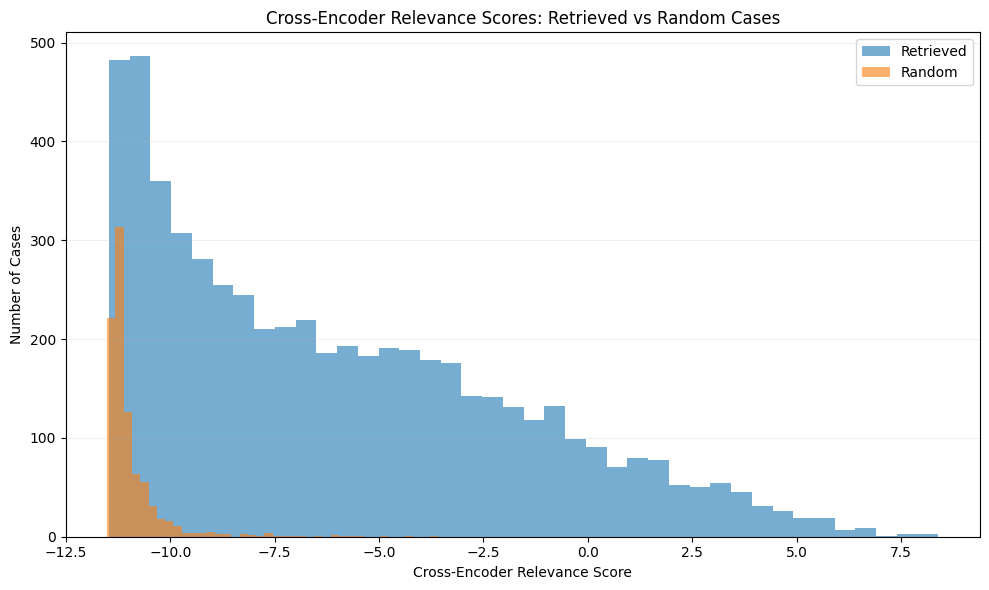

In [ ]:
plt.figure(figsize=(10, 6))

df_scores[df_scores["candidate_type"] == "retrieved"]["score"].plot(
    kind="hist",
    bins=40,
    alpha=0.6,
    label="Retrieved"
)

df_scores[df_scores["candidate_type"] == "random"]["score"].plot(
    kind="hist",
    bins=40,
    alpha=0.6,
    label="Random"
)

plt.xlabel("Cross-Encoder Relevance Score")
plt.ylabel("Number of Cases")
plt.title("Cross-Encoder Relevance Scores: Retrieved vs Random Cases")
plt.legend()
plt.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

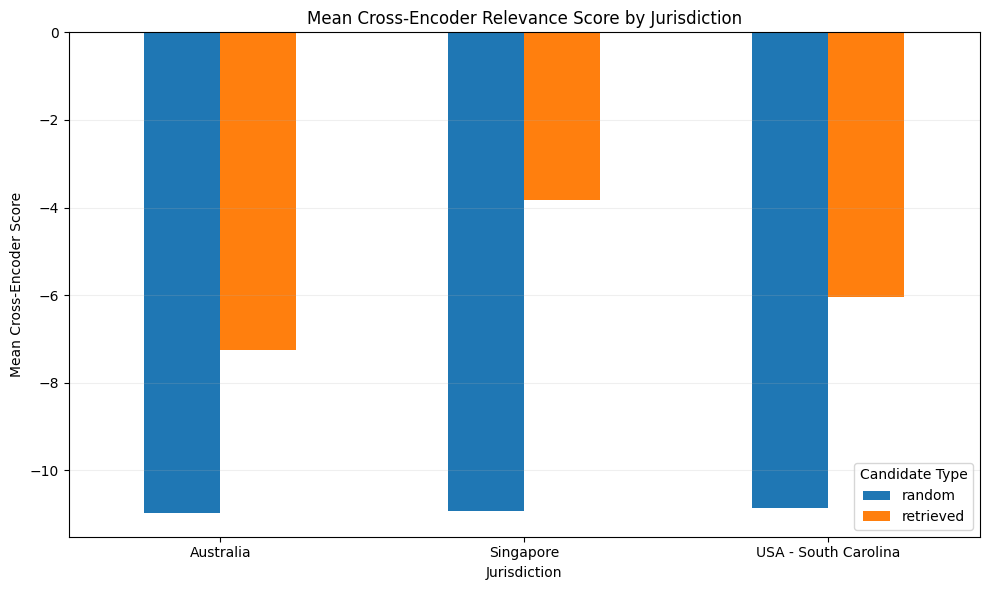

In [ ]:
plot_data = (
    df_scores
    .groupby(["jurisdiction", "candidate_type"])["score"]
    .mean()
    .unstack()
)

ax = plot_data.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.xlabel("Jurisdiction")
plt.ylabel("Mean Cross-Encoder Score")
plt.title("Mean Cross-Encoder Relevance Score by Jurisdiction")
plt.xticks(rotation=0)
plt.legend(title="Candidate Type")
plt.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

In [ ]:
import os
import json
import math
import numpy as np
import pandas as pd

from collections import defaultdict
from sentence_transformers import SentenceTransformer

import faiss
from whoosh.index import open_dir
from whoosh.qparser import QueryParser, OrGroup
from whoosh.query import Term

BASE = "/content/drive/MyDrive/legal_rag"

FAISS_FILE = os.path.join(
    BASE, "vector_store/legal_cases.index"
)

METADATA_FILE = os.path.join(
    BASE, "vector_store/metadata.jsonl"
)

BM25_DIR = os.path.join(
    BASE, "vector_store/bm25_index"
)

QUERY_FILE = os.path.join(
    BASE, "evaluation/evaluation_queries_final.json"
)

REFERENCE_FILE = os.path.join(
    BASE, "evaluation/model_assisted_relevance.json"
)

with open(QUERY_FILE, "r", encoding="utf-8") as f:
    queries = json.load(f)

with open(REFERENCE_FILE, "r", encoding="utf-8") as f:
    reference = json.load(f)

print("Queries:", len(queries))
print("Reference queries:", len(reference))


print("\nLoading metadata...")

metadata = []

with open(METADATA_FILE, "r", encoding="utf-8") as f:

    for line in f:

        line = line.strip()

        if line:
            metadata.append(json.loads(line))

print("Metadata records:", len(metadata))

chunk_to_case = {}

jurisdiction_positions = defaultdict(list)

for pos, item in enumerate(metadata):

    chunk_id = item.get("chunk_id")
    case_id = item.get("case_id")
    jurisdiction = item.get("jurisdiction")

    if chunk_id and case_id:
        chunk_to_case[chunk_id] = case_id

    if jurisdiction:
        jurisdiction_positions[
            jurisdiction
        ].append(pos)

print(
    "Chunk -> case mappings:",
    len(chunk_to_case)
)

print("\nJurisdiction vector counts:")

for jurisdiction, positions in jurisdiction_positions.items():
    print(
        jurisdiction,
        "->",
        len(positions)
    )


print("\nOpening BM25...")
bm25_index=bm25_idx
bm25_searcher = bm25_index.searcher()

parser = QueryParser(
    "text",
    schema=bm25_searcher.schema,
    group=OrGroup
)

print(
    "BM25 documents:",
    bm25_searcher.doc_count()
)

def dense_retrieve(
    query,
    jurisdiction,
    top_k=100
):

    positions = jurisdiction_positions.get(
        jurisdiction,
        []
    )

    if not positions:
        return []

    q_emb = embedding_model.encode(
        [query],
        normalize_embeddings=True,
        convert_to_numpy=True
    ).astype("float32")

    search_k = min(
        max(top_k * 20, 1000),
        faiss_index.ntotal
    )

    scores, indices = faiss_index.search(
        q_emb,
        search_k
    )

    allowed = set(positions)

    case_scores = {}

    for score, idx in zip(
        scores[0],
        indices[0]
    ):

        if idx < 0:
            continue

        if idx not in allowed:
            continue

        item = metadata[idx]

        case_id = item.get("case_id")

        if not case_id:
            continue

        score = float(score)

        if (
            case_id not in case_scores
            or score > case_scores[case_id]
        ):
            case_scores[case_id] = score

    ranked = sorted(
        case_scores.items(),
        key=lambda x: x[1],
        reverse=True
    )

    return ranked[:top_k]

def bm25_retrieve(
    query,
    jurisdiction,
    top_k=100
):

    parsed_query = parser.parse(query)

    combined_query = (
        parsed_query &
        Term(
            "jurisdiction",
            jurisdiction
        )
    )

    results = bm25_searcher.search(
        combined_query,
        limit=1000
    )

    case_scores = {}

    for result in results:

        chunk_id = result.get(
            "chunk_id"
        )

        if not chunk_id:
            continue

        case_id = chunk_to_case.get(
            chunk_id
        )

        if not case_id:
            continue

        score = float(
            result.score
        )

        if (
            case_id not in case_scores
            or score > case_scores[case_id]
        ):
            case_scores[case_id] = score

    ranked = sorted(
        case_scores.items(),
        key=lambda x: x[1],
        reverse=True
    )

    return ranked[:top_k]

def minmax_normalize(ranked):

    if not ranked:
        return {}

    scores = [
        score
        for _, score in ranked
    ]

    min_score = min(scores)
    max_score = max(scores)

    if max_score == min_score:

        return {
            case_id: 1.0
            for case_id, _ in ranked
        }

    return {
        case_id:
        (score - min_score) /
        (max_score - min_score)

        for case_id, score in ranked
    }

def get_rankings(
    query,
    jurisdiction
):

    dense = dense_retrieve(
        query,
        jurisdiction,
        top_k=100
    )

    bm25 = bm25_retrieve(
        query,
        jurisdiction,
        top_k=100
    )

    dense_norm = minmax_normalize(
        dense
    )

    bm25_norm = minmax_normalize(
        bm25
    )

    bm25_ranking = [
        case_id
        for case_id, _ in bm25
    ]

    dense_ranking = [
        case_id
        for case_id, _ in dense
    ]

    all_cases = (
        set(dense_norm) |
        set(bm25_norm)
    )

    hybrid_scores = {}

    for case_id in all_cases:

        dense_score = dense_norm.get(
            case_id,
            0.0
        )

        bm25_score = bm25_norm.get(
            case_id,
            0.0
        )

        hybrid_scores[case_id] = (
            0.5 * dense_score +
            0.5 * bm25_score
        )

    hybrid_ranking = [
        case_id
        for case_id, _ in sorted(
            hybrid_scores.items(),
            key=lambda x: x[1],
            reverse=True
        )
    ]

    return {
        "BM25": bm25_ranking,
        "Dense": dense_ranking,
        "Hybrid": hybrid_ranking
    }

def recall_at_k(
    ranking,
    relevant,
    k
):

    if not relevant:
        return 0.0

    retrieved = set(
        ranking[:k]
    )

    return (
        len(retrieved & relevant)
        / len(relevant)
    )


def reciprocal_rank(
    ranking,
    relevant
):

    for rank, case_id in enumerate(
        ranking,
        start=1
    ):

        if case_id in relevant:
            return 1.0 / rank

    return 0.0


def dcg_at_k(
    ranking,
    graded_relevance,
    k
):

    dcg = 0.0

    for rank, case_id in enumerate(
        ranking[:k],
        start=1
    ):

        rel = graded_relevance.get(
            case_id,
            0
        )

        dcg += (
            (2 ** rel - 1)
            / math.log2(rank + 1)
        )

    return dcg


def ndcg_at_k(
    ranking,
    graded_relevance,
    k
):

    dcg = dcg_at_k(
        ranking,
        graded_relevance,
        k
    )

    ideal_relevances = sorted(
        graded_relevance.values(),
        reverse=True
    )[:k]

    idcg = 0.0

    for rank, rel in enumerate(
        ideal_relevances,
        start=1
    ):

        idcg += (
            (2 ** rel - 1)
            / math.log2(rank + 1)
        )

    if idcg == 0:
        return 0.0

    return dcg / idcg


def average_precision(
    ranking,
    relevant
):

    if not relevant:
        return 0.0

    hits = 0
    precision_sum = 0.0

    for rank, case_id in enumerate(
        ranking,
        start=1
    ):

        if case_id in relevant:

            hits += 1

            precision_sum += (
                hits / rank
            )

    return (
        precision_sum
        / len(relevant)
    )

rows = []

print("\nStarting evaluation...")
print("=" * 70)

for i, q in enumerate(
    queries,
    start=1
):

    qid = q["query_id"]

    query = q["query"]

    jurisdiction = q[
        "jurisdiction"
    ]

    ref = reference[qid]

    relevant = set(
        ref["relevant_cases"]
    )

    graded = ref[
        "graded_relevance"
    ]

    rankings = get_rankings(
        query,
        jurisdiction
    )

    for method in [
        "BM25",
        "Dense",
        "Hybrid"
    ]:

        ranking = rankings[
            method
        ]

        rows.append({

            "query_id":
                qid,

            "jurisdiction":
                jurisdiction,

            "method":
                method,

            "Recall@1":
                recall_at_k(
                    ranking,
                    relevant,
                    1
                ),

            "Recall@5":
                recall_at_k(
                    ranking,
                    relevant,
                    5
                ),

            "Recall@10":
                recall_at_k(
                    ranking,
                    relevant,
                    10
                ),

            "Recall@20":
                recall_at_k(
                    ranking,
                    relevant,
                    20
                ),

            "MRR":
                reciprocal_rank(
                    ranking,
                    relevant
                ),

            "nDCG@10":
                ndcg_at_k(
                    ranking,
                    graded,
                    10
                ),

            "MAP":
                average_precision(
                    ranking,
                    relevant
                )
        })

    if i % 10 == 0:
        print(
            f"Processed {i}/{len(queries)}"
        )

results_df = pd.DataFrame(
    rows
)

print("\nEvaluation complete.")

print(
    "Rows:",
    len(results_df)
)


metric_cols = [
    "Recall@1",
    "Recall@5",
    "Recall@10",
    "Recall@20",
    "MRR",
    "nDCG@10",
    "MAP"
]

overall = (
    results_df
    .groupby("method")[metric_cols]
    .mean()
    .reset_index()
)

print("\n")
print("=" * 70)
print("OVERALL RETRIEVAL RESULTS")
print("=" * 70)

display(
    overall.round(4)
)

jurisdiction_results = (
    results_df
    .groupby(
        [
            "jurisdiction",
            "method"
        ]
    )[metric_cols]
    .mean()
    .reset_index()
)

print("\n")
print("=" * 70)
print("JURISDICTION-WISE RESULTS")
print("=" * 70)

display(
    jurisdiction_results.round(4)
)

print("\n")
print("=" * 70)
print("BM25 SANITY CHECK")
print("=" * 70)

bm25_rows = results_df[
    results_df["method"] == "BM25"
]

print(
    "BM25 non-zero Recall@20:",
    (
        bm25_rows["Recall@20"] > 0
    ).sum(),
    "/",
    len(bm25_rows)
)

print(
    "BM25 mean MRR:",
    round(
        bm25_rows["MRR"].mean(),
        4
    )
)

OUTPUT = os.path.join(
    BASE,
    "evaluation/retrieval_results_main.csv"
)

OVERALL_OUTPUT = os.path.join(
    BASE,
    "evaluation/retrieval_results_overall.csv"
)

JUR_OUTPUT = os.path.join(
    BASE,
    "evaluation/retrieval_results_by_jurisdiction.csv"
)

results_df.to_csv(
    OUTPUT,
    index=False
)

overall.to_csv(
    OVERALL_OUTPUT,
    index=False
)

jurisdiction_results.to_csv(
    JUR_OUTPUT,
    index=False
)

print("\nSaved:")
print(OUTPUT)
print(OVERALL_OUTPUT)
print(JUR_OUTPUT)

Queries: 90
Reference queries: 90

Loading metadata...
Metadata records: 689259
Chunk -> case mappings: 199893

Jurisdiction vector counts:
USA - South Carolina -> 108527
Singapore -> 578147
Australia -> 2585

Opening BM25...
BM25 documents: 689259

Starting evaluation...
Processed 10/90
Processed 20/90
Processed 30/90
Processed 40/90
Processed 50/90
Processed 60/90
Processed 70/90
Processed 80/90
Processed 90/90

Evaluation complete.
Rows: 270


OVERALL RETRIEVAL RESULTS


,method,Recall@1,Recall@5,Recall@10,Recall@20,MRR,nDCG@10,MAP
0,BM25,0.0311,0.1389,0.2417,0.4011,0.7678,0.3663,0.3692
1,Dense,0.0411,0.1672,0.2878,0.4567,0.8868,0.4232,0.4361
2,Hybrid,0.0433,0.1844,0.3250,0.5278,0.9230,0.4946,0.5692




JURISDICTION-WISE RESULTS


,jurisdiction,method,Recall@1,Recall@5,Recall@10,Recall@20,MRR,nDCG@10,MAP
0,Australia,BM25,0.0350,0.1717,0.3083,0.5000,0.8256,0.4906,0.4996
1,Australia,Dense,0.0383,0.1417,0.1983,0.2267,0.8556,0.3444,0.1818
2,Australia,Hybrid,0.0433,0.1900,0.3383,0.5450,0.9333,0.5410,0.5538
3,Singapore,BM25,0.0283,0.1250,0.2217,0.3733,0.7019,0.3161,0.3311
4,Singapore,Dense,0.0483,0.2233,0.4217,0.7450,0.9750,0.6009,0.7776
5,Singapore,Hybrid,0.0433,0.2100,0.3617,0.5950,0.9233,0.5521,0.6731
6,USA - South Carolina,BM25,0.0300,0.1200,0.1950,0.3300,0.7759,0.2921,0.2770
7,USA - South Carolina,Dense,0.0367,0.1367,0.2433,0.3983,0.8299,0.3242,0.3491
8,USA - South Carolina,Hybrid,0.0433,0.1533,0.2750,0.4433,0.9122,0.3906,0.4808




BM25 SANITY CHECK
BM25 non-zero Recall@20: 90 / 90
BM25 mean MRR: 0.7678

Saved:
/content/drive/MyDrive/legal_rag/evaluation/retrieval_results_main.csv
/content/drive/MyDrive/legal_rag/evaluation/retrieval_results_overall.csv
/content/drive/MyDrive/legal_rag/evaluation/retrieval_results_by_jurisdiction.csv


In [ ]:
import os
import json
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from collections import defaultdict
from sentence_transformers import SentenceTransformer

import faiss
from whoosh.index import open_dir
from whoosh.qparser import QueryParser, OrGroup
from whoosh.query import Term

BASE = "/content/drive/MyDrive/legal_rag"

FAISS_FILE = os.path.join(
    BASE, "vector_store/legal_cases.index"
)

METADATA_FILE = os.path.join(
    BASE, "vector_store/metadata.jsonl"
)

BM25_DIR = os.path.join(
    BASE, "vector_store/bm25_index"
)

QUERY_FILE = os.path.join(
    BASE, "evaluation/evaluation_queries_final.json"
)

REFERENCE_FILE = os.path.join(
    BASE, "evaluation/model_assisted_relevance.json"
)

EVAL_DIR = os.path.join(
    BASE, "evaluation"
)


with open(QUERY_FILE, "r", encoding="utf-8") as f:
    queries = json.load(f)

with open(REFERENCE_FILE, "r", encoding="utf-8") as f:
    reference = json.load(f)

print("Queries:", len(queries))
print("Reference queries:", len(reference))


print("\nLoading FAISS...")

faiss_index = faiss.read_index(
    FAISS_FILE
)

print(
    "FAISS vectors:",
    faiss_index.ntotal
)

print("\nLoading metadata...")

metadata = []

with open(
    METADATA_FILE,
    "r",
    encoding="utf-8"
) as f:

    for line in f:

        line = line.strip()

        if line:
            metadata.append(
                json.loads(line)
            )

print(
    "Metadata records:",
    len(metadata)
)

chunk_to_case = {}

jurisdiction_positions = defaultdict(list)

for pos, item in enumerate(metadata):

    chunk_id = item.get(
        "chunk_id"
    )

    case_id = item.get(
        "case_id"
    )

    jurisdiction = item.get(
        "jurisdiction"
    )

    if chunk_id and case_id:

        chunk_to_case[
            chunk_id
        ] = case_id

    if jurisdiction:

        jurisdiction_positions[
            jurisdiction
        ].append(pos)


print(
    "Chunk -> case mappings:",
    len(chunk_to_case)
)

print("\nJurisdiction vector counts:")

for jurisdiction, positions in jurisdiction_positions.items():

    print(
        jurisdiction,
        "->",
        len(positions)
    )

print("\nOpening BM25...")

bm25_index = open_dir(
    BM25_DIR
)

bm25_searcher = bm25_index.searcher()

parser = QueryParser(
    "text",
    schema=bm25_searcher.schema,
    group=OrGroup
)

print(
    "BM25 documents:",
    bm25_searcher.doc_count()
)


def dense_retrieve(
    query,
    jurisdiction,
    top_k=100
):

    positions = jurisdiction_positions.get(
        jurisdiction,
        []
    )

    if not positions:
        return []

    query_embedding = embedding_model.encode(
        [query],
        normalize_embeddings=True,
        convert_to_numpy=True
    ).astype("float32")

    search_k = min(
        max(top_k * 20, 1000),
        faiss_index.ntotal
    )

    scores, indices = faiss_index.search(
        query_embedding,
        search_k
    )

    allowed = set(positions)

    case_scores = {}

    for score, idx in zip(
        scores[0],
        indices[0]
    ):

        if idx < 0:
            continue

        if idx not in allowed:
            continue

        item = metadata[idx]

        case_id = item.get(
            "case_id"
        )

        if not case_id:
            continue

        score = float(score)

        if (
            case_id not in case_scores
            or score > case_scores[case_id]
        ):

            case_scores[
                case_id
            ] = score

    ranked = sorted(
        case_scores.items(),
        key=lambda x: x[1],
        reverse=True
    )

    return ranked[:top_k]

def bm25_retrieve(
    query,
    jurisdiction,
    top_k=100
):

    parsed_query = parser.parse(
        query
    )

    combined_query = (
        parsed_query &
        Term(
            "jurisdiction",
            jurisdiction
        )
    )

    results = bm25_searcher.search(
        combined_query,
        limit=1000
    )

    case_scores = {}

    for result in results:

        chunk_id = result.get(
            "chunk_id"
        )

        if not chunk_id:
            continue

        case_id = chunk_to_case.get(
            chunk_id
        )

        if not case_id:
            continue

        score = float(
            result.score
        )

        if (
            case_id not in case_scores
            or score > case_scores[case_id]
        ):

            case_scores[
                case_id
            ] = score

    ranked = sorted(
        case_scores.items(),
        key=lambda x: x[1],
        reverse=True
    )

    return ranked[:top_k]

def minmax_normalize(
    ranked
):

    if not ranked:
        return {}

    scores = [
        score
        for _, score in ranked
    ]

    min_score = min(scores)
    max_score = max(scores)

    if max_score == min_score:

        return {
            case_id: 1.0
            for case_id, _ in ranked
        }

    return {

        case_id:
        (
            (score - min_score)
            /
            (max_score - min_score)
        )

        for case_id, score in ranked
    }


print("\n")
print("=" * 70)
print("BUILDING RETRIEVAL CACHE")
print("=" * 70)

retrieval_cache = {}

for i, q in enumerate(
    queries,
    start=1
):

    qid = q["query_id"]

    query = q["query"]

    jurisdiction = q[
        "jurisdiction"
    ]

    dense = dense_retrieve(
        query,
        jurisdiction,
        top_k=100
    )

    bm25 = bm25_retrieve(
        query,
        jurisdiction,
        top_k=100
    )

    dense_norm = minmax_normalize(
        dense
    )

    bm25_norm = minmax_normalize(
        bm25
    )

    retrieval_cache[qid] = {

        "query": query,

        "jurisdiction":
            jurisdiction,

        "dense":
            dense_norm,

        "bm25":
            bm25_norm,

        "dense_ranking":
            [x[0] for x in dense],

        "bm25_ranking":
            [x[0] for x in bm25]
    }

    if i % 10 == 0:

        print(
            f"Cached {i}/{len(queries)}"
        )

with open("/content/drive/MyDrive/legal_rag/cache/retrieval_cache.json","w",encoding="utf-8") as f:
  json.dump(retrieval_cache, f, ensure_ascii=False,indent=2)

Queries: 90
Reference queries: 90

Loading FAISS...
FAISS vectors: 689259

Loading metadata...
Metadata records: 689259
Chunk -> case mappings: 199893

Jurisdiction vector counts:
USA - South Carolina -> 108527
Singapore -> 578147
Australia -> 2585

Opening BM25...
BM25 documents: 689259


BUILDING RETRIEVAL CACHE
Cached 10/90
Cached 20/90
Cached 30/90
Cached 40/90
Cached 50/90
Cached 60/90
Cached 70/90
Cached 80/90
Cached 90/90


In [ ]:
import os
import json
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from collections import defaultdict
from sentence_transformers import SentenceTransformer

import faiss
from whoosh.index import open_dir
from whoosh.qparser import QueryParser, OrGroup
from whoosh.query import Term

def recall_at_k(
    ranking,
    relevant,
    k
):

    if not relevant:
        return 0.0

    retrieved = set(
        ranking[:k]
    )

    return (
        len(
            retrieved & relevant
        )
        /
        len(relevant)
    )


def reciprocal_rank(
    ranking,
    relevant
):

    for rank, case_id in enumerate(
        ranking,
        start=1
    ):

        if case_id in relevant:

            return 1.0 / rank

    return 0.0


def dcg_at_k(
    ranking,
    graded_relevance,
    k
):

    dcg = 0.0

    for rank, case_id in enumerate(
        ranking[:k],
        start=1
    ):

        rel = graded_relevance.get(
            case_id,
            0
        )

        dcg += (
            (2 ** rel - 1)
            /
            math.log2(
                rank + 1
            )
        )

    return dcg


def ndcg_at_k(
    ranking,
    graded_relevance,
    k
):

    dcg = dcg_at_k(
        ranking,
        graded_relevance,
        k
    )

    ideal = sorted(
        graded_relevance.values(),
        reverse=True
    )[:k]

    idcg = 0.0

    for rank, rel in enumerate(
        ideal,
        start=1
    ):

        idcg += (
            (2 ** rel - 1)
            /
            math.log2(
                rank + 1
            )
        )

    if idcg == 0:

        return 0.0

    return dcg / idcg


def average_precision(
    ranking,
    relevant
):

    if not relevant:

        return 0.0

    hits = 0
    precision_sum = 0.0

    for rank, case_id in enumerate(
        ranking,
        start=1
    ):

        if case_id in relevant:

            hits += 1

            precision_sum += (
                hits / rank
            )

    return (
        precision_sum
        /
        len(relevant)
    )

alphas = [
    round(x, 1)
    for x in np.arange(
        0.0,
        1.01,
        0.1
    )
]

print(
    "\nAlpha values:",
    alphas
)

alpha_rows = []

print("\n")
print("=" * 70)
print("RUNNING ALPHA SENSITIVITY")
print("=" * 70)

for alpha in alphas:

    print(
        f"\nalpha = {alpha:.1f}"
    )

    for q in queries:

        qid = q["query_id"]

        jurisdiction = q[
            "jurisdiction"
        ]

        ref = reference[qid]

        relevant = set(
            ref["relevant_cases"]
        )

        graded = ref[
            "graded_relevance"
        ]

        cache = retrieval_cache[
            qid
        ]

        dense_scores = cache[
            "dense"
        ]

        bm25_scores = cache[
            "bm25"
        ]

        all_cases = (
            set(dense_scores)
            |
            set(bm25_scores)
        )

        hybrid_scores = {}

        for case_id in all_cases:

            dense_score = dense_scores.get(
                case_id,
                0.0
            )

            bm25_score = bm25_scores.get(
                case_id,
                0.0
            )

            hybrid_scores[
                case_id
            ] = (

                alpha * dense_score

                +

                (1 - alpha)
                * bm25_score
            )

        ranking = [
            case_id
            for case_id, score
            in sorted(
                hybrid_scores.items(),
                key=lambda x: x[1],
                reverse=True
            )
        ]

        alpha_rows.append({

            "query_id":
                qid,

            "jurisdiction":
                jurisdiction,

            "alpha":
                alpha,

            "Recall@1":
                recall_at_k(
                    ranking,
                    relevant,
                    1
                ),

            "Recall@5":
                recall_at_k(
                    ranking,
                    relevant,
                    5
                ),

            "Recall@10":
                recall_at_k(
                    ranking,
                    relevant,
                    10
                ),

            "Recall@20":
                recall_at_k(
                    ranking,
                    relevant,
                    20
                ),

            "MRR":
                reciprocal_rank(
                    ranking,
                    relevant
                ),

            "nDCG@10":
                ndcg_at_k(
                    ranking,
                    graded,
                    10
                ),

            "MAP":
                average_precision(
                    ranking,
                    relevant
                )
        })

alpha_df = pd.DataFrame(
    alpha_rows
)

print("\n")
print("=" * 70)
print("ALPHA SENSITIVITY COMPLETE")
print("=" * 70)

print(
    "Rows:",
    len(alpha_df)
)

print(
    "Expected:",
    90 * 11
)

metric_cols = [
    "Recall@1",
    "Recall@5",
    "Recall@10",
    "Recall@20",
    "MRR",
    "nDCG@10",
    "MAP"
]

alpha_overall = (
    alpha_df
    .groupby("alpha")[metric_cols]
    .mean()
    .reset_index()
)

print("\n")
print("=" * 70)
print("OVERALL ALPHA SENSITIVITY")
print("=" * 70)

display(
    alpha_overall.round(4)
)

alpha_jurisdiction = (
    alpha_df
    .groupby(
        [
            "jurisdiction",
            "alpha"
        ]
    )[metric_cols]
    .mean()
    .reset_index()
)

print("\n")
print("=" * 70)
print("JURISDICTION-WISE ALPHA SENSITIVITY")
print("=" * 70)

display(
    alpha_jurisdiction.round(4)
)

print("\n")
print("=" * 70)
print("BEST ALPHA VALUES")
print("=" * 70)

for metric in [
    "Recall@10",
    "Recall@20",
    "MRR",
    "nDCG@10",
    "MAP"
]:

    best_row = alpha_overall.loc[
        alpha_overall[metric].idxmax()
    ]

    print(
        f"{metric}: "
        f"alpha={best_row['alpha']:.1f} "
        f"value={best_row[metric]:.4f}"
    )

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    alpha_overall["alpha"],
    alpha_overall["Recall@20"],
    marker="o"
)

plt.xlabel(
    "Dense Weight (α)"
)

plt.ylabel(
    "Recall@10"
)

plt.title(
    "Effect of α on Recall@10"
)

plt.xticks(
    alphas
)

plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()

recall_plot = os.path.join(
    EVAL_DIR,
    "alpha_sensitivity_recall10.png"
)

plt.savefig(
    recall_plot,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

plt.figure(
    figsize=(8, 5)
)

plt.plot(
    alpha_overall["alpha"],
    alpha_overall["MRR"],
    marker="o"
)

plt.xlabel(
    "Dense Weight (α)"
)

plt.ylabel(
    "MRR"
)

plt.title(
    "Effect of α on MRR"
)

plt.xticks(
    alphas
)

plt.grid(
    True,
    alpha=0.3
)

plt.tight_layout()

mrr_plot = os.path.join(
    EVAL_DIR,
    "alpha_sensitivity_mrr.png"
)

plt.savefig(
    mrr_plot,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

alpha_df.to_csv(
    os.path.join(
        EVAL_DIR,
        "alpha_sensitivity_query_level.csv"
    ),
    index=False
)

alpha_overall.to_csv(
    os.path.join(
        EVAL_DIR,
        "alpha_sensitivity_overall.csv"
    ),
    index=False
)

alpha_jurisdiction.to_csv(
    os.path.join(
        EVAL_DIR,
        "alpha_sensitivity_by_jurisdiction.csv"
    ),
    index=False
)

print("\nSaved:")
print(
    os.path.join(
        EVAL_DIR,
        "alpha_sensitivity_query_level.csv"
    )
)

print(
    os.path.join(
        EVAL_DIR,
        "alpha_sensitivity_overall.csv"
    )
)

print(
    os.path.join(
        EVAL_DIR,
        "alpha_sensitivity_by_jurisdiction.csv"
    )
)

print(
    recall_plot
)

print(
    mrr_plot
)

In [ ]:
alpha_results = []

for alpha in np.arange(0, 1.01, 0.1):
    rows = []

    for query_id, ref in reference.items():

        if query_id not in retrieval_cache:
            continue

        entry = retrieval_cache[query_id]

        ranking = get_rankings(entry, round(alpha, 1))

        metrics = evaluate_ranking(
            ranking,
            ref["relevant_cases"]
        )

        rows.append(metrics)

    df = pd.DataFrame(rows)

    alpha_results.append({
        "alpha": round(alpha, 1),
        "Recall@10": df["r10"].mean(),
        "MRR": df["mrr"].mean(),
        "nDCG@10": df["ndcg10"].mean()
    })

alpha_table = pd.DataFrame(alpha_results)

display(alpha_table)

,alpha,Recall@10,MRR,nDCG@10
0,0.0,1.000000,0.769008,0.520266
1,0.1,1.000000,0.788082,0.539833
2,0.2,1.000000,0.820212,0.566317
3,0.3,1.000000,0.860582,0.603825
4,0.4,1.000000,0.889259,0.646237
5,0.5,1.000000,0.934074,0.698294
6,0.6,0.988889,0.919444,0.712223
7,0.7,0.988889,0.931209,0.711934
8,0.8,0.988889,0.923843,0.709779
9,0.9,0.988889,0.914583,0.695325


In [ ]:
import numpy as np
import pandas as pd

def evaluate_ranking(ranking, relevant, k_values=(1, 5, 10, 20)):
    relevant = set(str(x) for x in relevant)

    recalls = {}
    for k in k_values:
        recalls[k] = int(any(x in relevant for x in ranking[:k]))

    rr = 0
    for rank, case_id in enumerate(ranking, 1):
        if case_id in relevant:
            rr = 1 / rank
            break

    gains = [1 if x in relevant else 0 for x in ranking[:10]]

    dcg = sum(
        gain / np.log2(i + 2)
        for i, gain in enumerate(gains)
    )

    ideal = min(len(relevant), 10)

    idcg = sum(
        1 / np.log2(i + 2)
        for i in range(ideal)
    )

    ndcg = dcg / idcg if idcg else 0

    return {
        "r1": recalls[1],
        "r5": recalls[5],
        "r10": recalls[10],
        "r20": recalls[20],
        "mrr": rr,
        "ndcg10": ndcg
    }


def get_rankings(entry, alpha):
    dense = entry["dense"]
    bm25 = entry["bm25"]

    case_ids = set(dense) | set(bm25)

    hybrid_scores = {}

    for case_id in case_ids:
        d = dense.get(case_id, 0)
        b = bm25.get(case_id, 0)

        hybrid_scores[case_id] = (
            alpha * d +
            (1 - alpha) * b
        )

    return sorted(
        hybrid_scores,
        key=hybrid_scores.get,
        reverse=True
    )


def run_ablation(alpha):
    rows = []

    for query_id, ref in reference.items():

        if query_id not in retrieval_cache:
            continue

        entry = retrieval_cache[query_id]

        ranking = get_rankings(entry, alpha)

        metrics = evaluate_ranking(
            ranking,
            ref["relevant_cases"]
        )

        rows.append({
            "query_id": query_id,
            "query": ref["query"],
            "jurisdiction": ref["jurisdiction"],
            **metrics
        })

    return pd.DataFrame(rows)


ablation_configs = {
    "Semantic only": 1.0,
    "Lexical only": 0.0,
    "Hybrid (alpha=0.5)": 0.5,
    "Selected Hybrid (alpha=0.7)": 0.7
}

ablation_rows = []

for name, alpha in ablation_configs.items():

    df_ab = run_ablation(alpha)

    ablation_rows.append({
        "Configuration": name,
        "Recall@10": df_ab["r10"].mean(),
        "MRR": df_ab["mrr"].mean(),
        "nDCG@10": df_ab["ndcg10"].mean()
    })

ablation_table = pd.DataFrame(ablation_rows)

display(ablation_table)

,Configuration,Recall@10,MRR,nDCG@10
0,Semantic only,0.977778,0.887660,0.629895
1,Lexical only,1.000000,0.767822,0.520238
2,Hybrid (alpha=0.5),1.000000,0.911852,0.693992
3,Selected Hybrid (alpha=0.7),0.988889,0.931209,0.711934


In [ ]:
import pandas as pd
import numpy as np

def binary_metrics(ranking, relevant, k=10):
    relevant = set(str(x) for x in relevant)
    predicted = set(str(x) for x in ranking[:k])

    tp = len(predicted & relevant)
    fp = len(predicted - relevant)
    fn = len(relevant - predicted)

    precision = tp / (tp + fp) if (tp + fp) else 0
    recall = tp / (tp + fn) if (tp + fn) else 0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    return {
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    }


rows = []

for query_id, ref in reference.items():

    if query_id not in retrieval_cache:
        continue

    entry = retrieval_cache[query_id]

    ranking = get_rankings(entry, 0.7)

    metrics = binary_metrics(
        ranking,
        ref["relevant_cases"],
        k=10
    )

    rows.append({
        "query_id": query_id,
        "jurisdiction": ref["jurisdiction"],
        **metrics
    })

binary_query_results = pd.DataFrame(rows)

binary_by_jurisdiction = (
    binary_query_results
    .groupby("jurisdiction")
    .agg({
        "TP": "mean",
        "FP": "mean",
        "FN": "mean",
        "Precision": "mean",
        "Recall": "mean",
        "F1": "mean"
    })
    .reset_index()
)

display(binary_by_jurisdiction)

,jurisdiction,TP,FP,FN,Precision,Recall,F1
0,Australia,6.4,3.6,13.6,0.64,0.320,0.426667
1,Singapore,8.4,1.6,11.6,0.84,0.420,0.560000
2,USA - South Carolina,5.3,4.7,14.7,0.53,0.265,0.353333


In [ ]:
import json
import pandas as pd
import numpy as np

citation_path = "/content/drive/MyDrive/legal_rag/cache/case_citation_counts_corrected.json"

with open(citation_path, "r") as f:
    citation_counts = json.load(f)

max_cc = max(citation_counts.values()) if citation_counts else 1

def get_citation_score(case_id):
    return citation_counts.get(str(case_id), 0) / max_cc


def get_influence_ranking(entry, alpha=0.7, beta=0.5):
    dense = entry["dense"]
    bm25 = entry["bm25"]

    case_ids = set(dense) | set(bm25)

    hybrid_scores = {}
    citation_scores = {}

    for case_id in case_ids:
        d = dense.get(case_id, 0)
        b = bm25.get(case_id, 0)

        hybrid_scores[case_id] = (
            alpha * d + (1 - alpha) * b
        )

        citation_scores[case_id] = get_citation_score(case_id)

    influence_scores = {}

    for case_id in case_ids:
        influence_scores[case_id] = (
            beta * citation_scores[case_id]
            + (1 - beta) * hybrid_scores[case_id]
        )

    gamma = 0.5

    final_scores = {}

    for case_id in case_ids:
        final_scores[case_id] = (
            gamma * hybrid_scores[case_id]
            + (1 - gamma) * influence_scores[case_id]
        )

    return sorted(
        final_scores,
        key=final_scores.get,
        reverse=True
    )


def evaluate_beta(beta):
    rows = []

    for query_id, ref in reference.items():

        if query_id not in retrieval_cache:
            continue

        entry = retrieval_cache[query_id]

        ranking = get_influence_ranking(
            entry,
            alpha=0.7,
            beta=beta
        )

        metrics = evaluate_ranking(
            ranking,
            ref["relevant_cases"]
        )

        rows.append({
            "query_id": query_id,
            "jurisdiction": ref["jurisdiction"],
            **metrics
        })

    df = pd.DataFrame(rows)

    return {
        "beta": beta,
        "Recall@10": df["r10"].mean(),
        "MRR": df["mrr"].mean(),
        "nDCG@10": df["ndcg10"].mean()
    }


beta_results = []

for beta in np.arange(0, 1.01, 0.1):
    beta_results.append(evaluate_beta(round(beta, 1)))

beta_table = pd.DataFrame(beta_results)

display(beta_table)

,beta,Recall@10,MRR,nDCG@10
0,0.0,0.988889,0.931209,0.711934
1,0.1,0.988889,0.931209,0.711687
2,0.2,0.988889,0.925585,0.712153
3,0.3,0.988889,0.925529,0.710438
4,0.4,0.988889,0.926455,0.708245
5,0.5,0.988889,0.917196,0.706100
6,0.6,0.988889,0.915344,0.703510
7,0.7,0.988889,0.909788,0.700855
8,0.8,0.988889,0.908816,0.689744
9,0.9,0.988889,0.888838,0.679362


In [ ]:
def get_final_ranking(entry, alpha=0.7, beta=0.2, gamma=0.5):
    dense = entry["dense"]
    bm25 = entry["bm25"]

    case_ids = set(dense) | set(bm25)

    hybrid_scores = {}
    citation_scores = {}

    for case_id in case_ids:
        d = dense.get(case_id, 0)
        b = bm25.get(case_id, 0)

        hybrid_scores[case_id] = (
            alpha * d + (1 - alpha) * b
        )

        citation_scores[case_id] = get_citation_score(case_id)

    influence_scores = {}

    for case_id in case_ids:
        influence_scores[case_id] = (
            beta * citation_scores[case_id]
            + (1 - beta) * hybrid_scores[case_id]
        )

    final_scores = {}

    for case_id in case_ids:
        final_scores[case_id] = (
            gamma * hybrid_scores[case_id]
            + (1 - gamma) * influence_scores[case_id]
        )

    return sorted(
        final_scores,
        key=final_scores.get,
        reverse=True
    )


def evaluate_gamma(gamma):
    rows = []

    for query_id, ref in reference.items():

        if query_id not in retrieval_cache:
            continue

        entry = retrieval_cache[query_id]

        ranking = get_final_ranking(
            entry,
            alpha=0.7,
            beta=0.2,
            gamma=gamma
        )

        metrics = evaluate_ranking(
            ranking,
            ref["relevant_cases"]
        )

        rows.append({
            "query_id": query_id,
            "jurisdiction": ref["jurisdiction"],
            **metrics
        })

    df = pd.DataFrame(rows)

    return {
        "gamma": gamma,
        "Recall@10": df["r10"].mean(),
        "MRR": df["mrr"].mean(),
        "nDCG@10": df["ndcg10"].mean()
    }


gamma_results = []

for gamma in np.arange(0, 1.01, 0.1):
    gamma_results.append(
        evaluate_gamma(round(gamma, 1))
    )

gamma_table = pd.DataFrame(gamma_results)

display(gamma_table)

,gamma,Recall@10,MRR,nDCG@10
0,0.0,0.988889,0.926455,0.708245
1,0.1,0.988889,0.925529,0.710520
2,0.2,0.988889,0.925529,0.710231
3,0.3,0.988889,0.925529,0.709696
4,0.4,0.988889,0.925556,0.710582
5,0.5,0.988889,0.925585,0.712153
6,0.6,0.988889,0.925654,0.711311
7,0.7,0.988889,0.931209,0.712371
8,0.8,0.988889,0.931209,0.711775
9,0.9,0.988889,0.931209,0.712851


In [ ]:
final_configs = [
    ("Semantic only", 1.0, 0.0, 1.0),
    ("Lexical only", 0.0, 0.0, 1.0),
    ("Hybrid (alpha=0.5)", 0.5, 0.0, 1.0),
    ("Hybrid (alpha=0.7)", 0.7, 0.0, 1.0),
    ("Hybrid + Citation (beta=0.2)", 0.7, 0.2, 1.0),
    ("Full System", 0.7, 0.2, 0.9)
]

final_rows = []

for name, alpha, beta, gamma in final_configs:

    rows = []

    for query_id, ref in reference.items():

        if query_id not in retrieval_cache:
            continue

        entry = retrieval_cache[query_id]

        ranking = get_final_ranking(
            entry,
            alpha=alpha,
            beta=beta,
            gamma=gamma
        )

        metrics = evaluate_ranking(
            ranking,
            ref["relevant_cases"]
        )

        rows.append(metrics)

    df = pd.DataFrame(rows)

    final_rows.append({
        "Configuration": name,
        "Recall@10": df["r10"].mean(),
        "MRR": df["mrr"].mean(),
        "nDCG@10": df["ndcg10"].mean()
    })

final_comparison = pd.DataFrame(final_rows)

display(final_comparison)

,Configuration,Recall@10,MRR,nDCG@10
0,Semantic only,0.988889,0.890509,0.637129
1,Lexical only,1.000000,0.769008,0.520266
2,Hybrid (alpha=0.5),1.000000,0.934074,0.698294
3,Hybrid (alpha=0.7),0.988889,0.931209,0.711934
4,Hybrid + Citation (beta=0.2),0.988889,0.931209,0.711934
5,Full System,0.988889,0.931209,0.712851


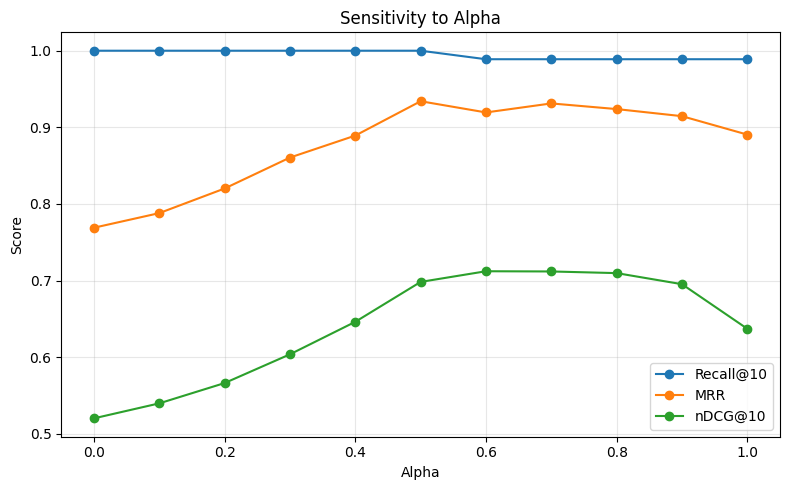

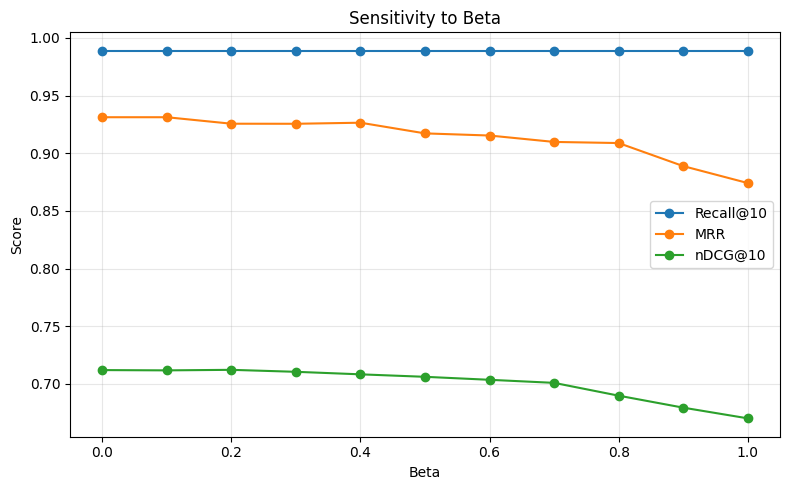

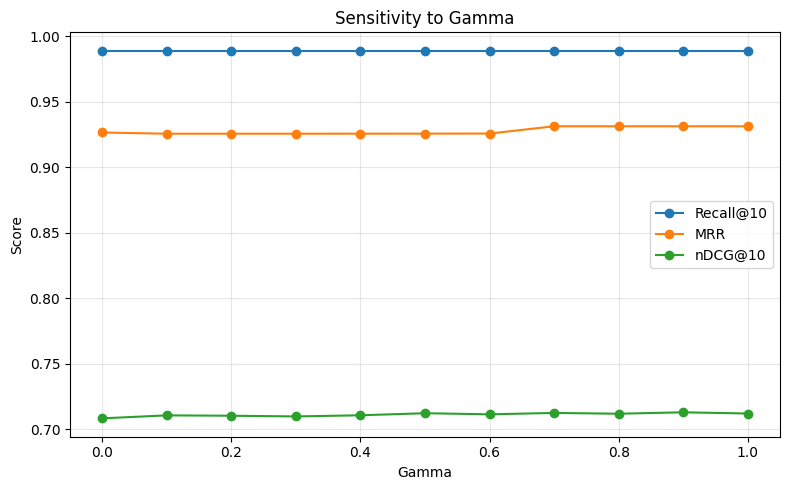

In [ ]:
import matplotlib.pyplot as plt

plot_dir = "/content/drive/MyDrive/legal_rag/evaluation"

# Alpha sensitivity
plt.figure(figsize=(8, 5))
plt.plot(alpha_table["alpha"], alpha_table["Recall@10"], marker="o", label="Recall@10")
plt.plot(alpha_table["alpha"], alpha_table["MRR"], marker="o", label="MRR")
plt.plot(alpha_table["alpha"], alpha_table["nDCG@10"], marker="o", label="nDCG@10")
plt.xlabel("Alpha")
plt.ylabel("Score")
plt.title("Sensitivity to Alpha")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# Beta sensitivity
plt.figure(figsize=(8, 5))
plt.plot(beta_table["beta"], beta_table["Recall@10"], marker="o", label="Recall@10")
plt.plot(beta_table["beta"], beta_table["MRR"], marker="o", label="MRR")
plt.plot(beta_table["beta"], beta_table["nDCG@10"], marker="o", label="nDCG@10")
plt.xlabel("Beta")
plt.ylabel("Score")
plt.title("Sensitivity to Beta")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# Gamma sensitivity
plt.figure(figsize=(8, 5))
plt.plot(gamma_table["gamma"], gamma_table["Recall@10"], marker="o", label="Recall@10")
plt.plot(gamma_table["gamma"], gamma_table["MRR"], marker="o", label="MRR")
plt.plot(gamma_table["gamma"], gamma_table["nDCG@10"], marker="o", label="nDCG@10")
plt.xlabel("Gamma")
plt.ylabel("Score")
plt.title("Sensitivity to Gamma")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import roc_auc_score
from scipy.stats import spearmanr, pearsonr

OUTPUT_DIR = "evaluation/additional_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)


def normalize_ids(items):
    """Convert reference case IDs to a consistent string set."""
    result = set()

    for item in items:
        if isinstance(item, dict):
            item = item.get("case_id", item.get("id", item.get("case")))
        if item is not None:
            result.add(str(item))

    return result


def binary_metrics(ranking, relevant, k=10):
    relevant = normalize_ids(relevant)
    ranking = list(dict.fromkeys(str(x) for x in ranking))[:k]

    tp = len(set(ranking) & relevant)
    fp = len(set(ranking) - relevant)
    fn = len(relevant - set(ranking))

    precision = tp / len(ranking) if ranking else 0
    recall = tp / len(relevant) if relevant else 0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    return {
        "TP": tp, "FP": fp, "FN": fn,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    }


def ranking_metrics(ranking, relevant, k=10):
    relevant = normalize_ids(relevant)
    ranking = list(dict.fromkeys(str(x) for x in ranking))

    binary = binary_metrics(ranking, relevant, k)
    top_k = ranking[:k]

    reciprocal_rank = 0.0
    for rank, case_id in enumerate(ranking, start=1):
        if case_id in relevant:
            reciprocal_rank = 1 / rank
            break

    dcg = sum(
        1 / np.log2(rank + 1)
        for rank, case_id in enumerate(top_k, start=1)
        if case_id in relevant
    )

    ideal_hits = min(len(relevant), k)
    idcg = sum(
        1 / np.log2(rank + 1)
        for rank in range(1, ideal_hits + 1)
    )

    return {
        **binary,
        "MRR": reciprocal_rank,
        f"nDCG@{k}": dcg / idcg if idcg else 0
    }

In [ ]:
with open("/content/drive/MyDrive/legal_rag/cache/retrieval_cache.json", "r") as f:
    retrieval_cache = json.load(f)

In [ ]:
def score_map_to_ranking(score_map):
    return [
        str(case_id)
        for case_id, score in sorted(
            score_map.items(),
            key=lambda x: float(x[1]),
            reverse=True
        )
    ]
K=10

def rrf_ranking(entry, rrf_k=60):
    dense_map = entry["dense"]
    bm25_map = entry["bm25"]

    dense_ranking = score_map_to_ranking(dense_map)
    bm25_ranking = score_map_to_ranking(bm25_map)

    rrf_scores = {}

    for ranking in (dense_ranking, bm25_ranking):
        for rank, case_id in enumerate(ranking, start=1):
            rrf_scores[case_id] = (
                rrf_scores.get(case_id, 0.0)
                + 1.0 / (rrf_k + rank)
            )

    return sorted(
        rrf_scores,
        key=lambda case_id: rrf_scores[case_id],
        reverse=True
    )


rrf_rows = []

for rrf_k in [10, 20, 30, 40, 60, 80, 100]:
    for query_id, ref in reference.items():
        if query_id not in retrieval_cache:
            continue

        ranking = rrf_ranking(
            retrieval_cache[query_id],
            rrf_k=rrf_k
        )

        metrics = ranking_metrics(
            ranking,
            ref["relevant_cases"],
            k=K
        )

        rrf_rows.append({
            "query_id": query_id,
            "jurisdiction": ref["jurisdiction"],
            "rrf_k": rrf_k,
            **metrics
        })

rrf_query_results = pd.DataFrame(rrf_rows)

rrf_summary = (
    rrf_query_results
    .groupby("rrf_k")[
        ["Precision", "Recall", "F1", "MRR", f"nDCG@{K}"]
    ]
    .mean()
    .reset_index()
)

display(rrf_summary)

rrf_query_results.to_csv(
    f"{OUTPUT_DIR}/rrf_per_query.csv", index=False
)
rrf_summary.to_csv(
    f"{OUTPUT_DIR}/rrf_sensitivity_summary.csv", index=False
)

,rrf_k,Precision,Recall,F1,MRR,nDCG@10
0,10,0.633333,0.316667,0.422222,0.931481,0.687432
1,20,0.634444,0.317222,0.422963,0.944444,0.693449
2,30,0.635556,0.317778,0.423704,0.947222,0.694649
3,40,0.632222,0.316111,0.421481,0.952778,0.691869
4,60,0.626667,0.313333,0.417778,0.952778,0.685856
5,80,0.618889,0.309444,0.412593,0.958333,0.680720
6,100,0.615556,0.307778,0.410370,0.958333,0.678243


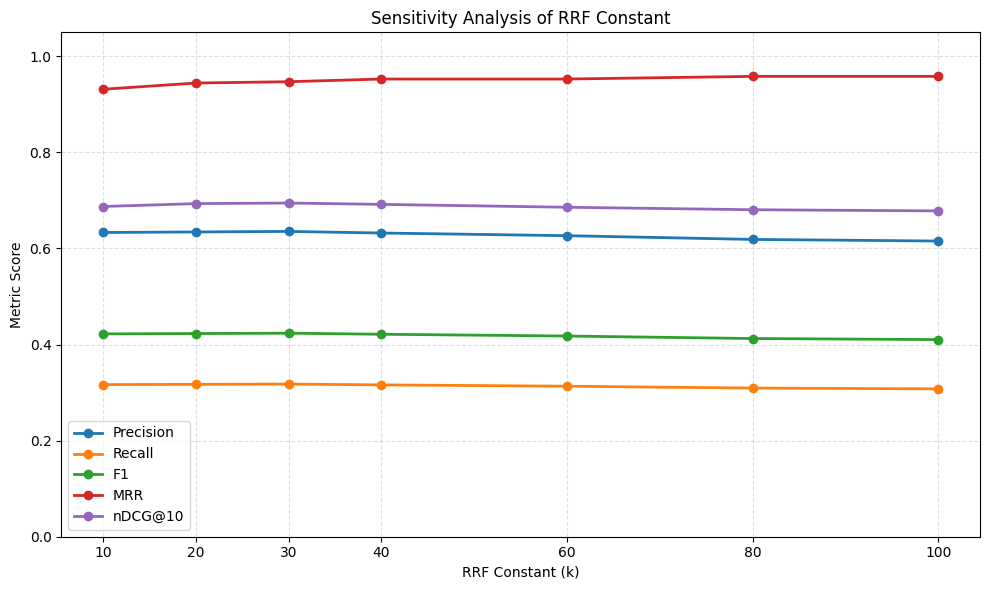

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import os

# If your dataframe has a different name, replace it here.
rrf_plot_df = rrf_summary.copy()

metrics = ["Precision", "Recall", "F1", "MRR", "nDCG@10"]

plt.figure(figsize=(10, 6))

for metric in metrics:
    plt.plot(
        rrf_plot_df["rrf_k"],
        rrf_plot_df[metric],
        marker="o",
        linewidth=2,
        label=metric
    )

plt.xlabel("RRF Constant (k)")
plt.ylabel("Metric Score")
plt.title("Sensitivity Analysis of RRF Constant")
plt.xticks(rrf_plot_df["rrf_k"])
plt.ylim(0, 1.05)
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend()
plt.tight_layout()
plt.savefig("rrf_sensitivity.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
import time

query_rows = []

for query_id, ref in reference.items():
    if query_id not in retrieval_cache:
        continue

    entry = retrieval_cache[query_id]

    start = time.perf_counter()
    ranking = get_rankings(entry, 0.7)
    scoring_time_ms = (time.perf_counter() - start) * 1000

    metrics = ranking_metrics(
        ranking,
        ref["relevant_cases"],
        k=K
    )

    query_rows.append({
        "query_id": query_id,
        "jurisdiction": ref["jurisdiction"],
        "query": ref.get("query", ""),
        "num_relevant": len(normalize_ids(ref["relevant_cases"])),
        "scoring_time_ms": scoring_time_ms,
        **metrics
    })

per_query = pd.DataFrame(query_rows)

metric_columns = [
    "Precision", "Recall", "F1", "MRR",
    f"nDCG@{K}", "scoring_time_ms"
]

per_jurisdiction = (
    per_query.groupby("jurisdiction")[metric_columns]
    .agg(["mean", "std", "median"])
)

display(per_query.head())
display(per_jurisdiction)

per_query.to_csv(
    f"{OUTPUT_DIR}/per_query_metrics.csv", index=False
)
per_jurisdiction.to_csv(
    f"{OUTPUT_DIR}/per_jurisdiction_metrics.csv"
)

,query_id,jurisdiction,query,num_relevant,scoring_time_ms,TP,FP,FN,Precision,Recall,F1,MRR,nDCG@10
0,AUS_001,Australia,What is the legal test for negligence?,20,0.09779,7,3,13,0.7,0.35,0.466667,1.0,0.796761
1,AUS_002,Australia,What are the elements required to establish ne...,20,0.05885,4,6,16,0.4,0.20,0.266667,1.0,0.538886
2,AUS_003,Australia,When does a duty of care arise?,20,0.04867,5,5,15,0.5,0.25,0.333333,1.0,0.617764
3,AUS_004,Australia,When can a defendant be held liable for breach...,20,0.04718,3,7,17,0.3,0.15,0.200000,1.0,0.437352
4,AUS_005,Australia,How is causation determined in negligence cases?,20,0.04585,10,0,10,1.0,0.50,0.666667,1.0,1.000000


Precision                  Recall                   \
                          mean       std median   mean       std median   
jurisdiction                                                              
Australia                 0.64  0.194049   0.70  0.320  0.097025  0.350   
Singapore                 0.84  0.161031   0.90  0.420  0.080516  0.450   
USA - South Carolina      0.53  0.208690   0.55  0.265  0.104345  0.275   

                            F1                           MRR                   \
                          mean       std    median      mean       std median   
jurisdiction                                                                    
Australia             0.426667  0.129366  0.466667  0.950000  0.152564    1.0   
Singapore             0.560000  0.107354  0.600000  0.975000  0.136931    1.0   
USA - South Carolina  0.353333  0.139127  0.366667  0.868627  0.278113    1.0   

                       nDCG@10                     scoring_time_ms            \
                          mean       std    median            mean       std   
jurisdiction                                                                   
Australia             0.690574  0.165633  0.697008        0.050479  0.010729   
Singapore             0.867018  0.151562  0.914857        0.073311  0.012863   
USA - South Carolina  0.578210  0.222724  0.620198        0.089987  0.043937   

                                
                        median  
jurisdiction                    
Australia             0.049075  
Singapore             0.070715  
USA - South Carolina  0.083475

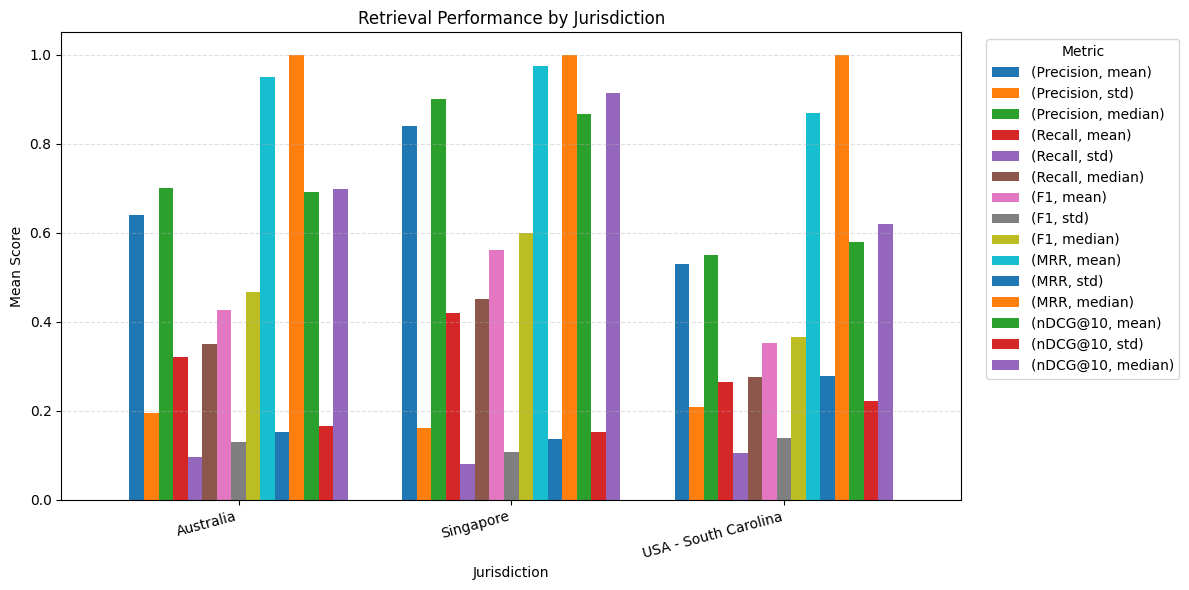

In [ ]:
# Replace jurisdiction_summary with your actual dataframe name.
jurisdiction_plot_df = per_jurisdiction.copy()

metrics = ["Precision", "Recall", "F1", "MRR", "nDCG@10"]

# Handle jurisdiction names stored in the index
if "jurisdiction" not in jurisdiction_plot_df.columns:
    jurisdiction_plot_df = jurisdiction_plot_df.reset_index()

jurisdiction_plot_df = jurisdiction_plot_df.set_index("jurisdiction")

ax = jurisdiction_plot_df[metrics].plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

ax.set_title("Retrieval Performance by Jurisdiction")
ax.set_xlabel("Jurisdiction")
ax.set_ylabel("Mean Score")
ax.set_ylim(0, 1.05)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.legend(title="Metric", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.savefig("jurisdiction_performance.png", dpi=300, bbox_inches="tight")
plt.show()

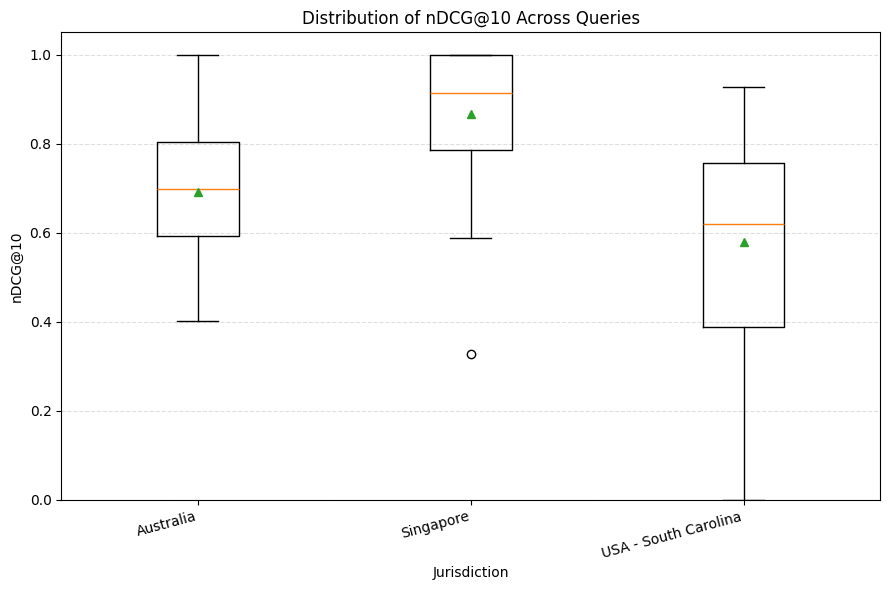

In [ ]:
# Replace query_results with your per-query dataframe variable.
query_plot_df = per_query.copy()

plt.figure(figsize=(9, 6))

jurisdictions = query_plot_df["jurisdiction"].unique()
box_data = [
    query_plot_df.loc[
        query_plot_df["jurisdiction"] == j, "nDCG@10"
    ].dropna()
    for j in jurisdictions
]

plt.boxplot(box_data, tick_labels=jurisdictions, showmeans=True)

plt.title("Distribution of nDCG@10 Across Queries")
plt.xlabel("Jurisdiction")
plt.ylabel("nDCG@10")
plt.ylim(0, 1.05)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.savefig("query_level_ndcg_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
CITATION_FILE = "/content/drive/MyDrive/legal_rag/cache/case_citation_counts_corrected.json"

with open(CITATION_FILE, "r", encoding="utf-8") as f:
    citation_data = json.load(f)


def extract_citation_counts(data):
    """
    Supports either:
      {"case_id": 12, ...}
    or:
      {"case_id": {"citation_count": 12}, ...}

    Adjust this function if your JSON uses another schema.
    """
    if isinstance(data, dict) and "citation_counts" in data:
        data = data["citation_counts"]

    counts = {}

    for case_id, value in data.items():
        if isinstance(value, dict):
            value = value.get(
                "citation_count",
                value.get("count", value.get("CC", 0))
            )

        try:
            counts[str(case_id)] = float(value)
        except (TypeError, ValueError):
            continue

    return counts


citation_counts = extract_citation_counts(citation_data)

citation_rows = []

for query_id, ref in reference.items():
    if query_id not in retrieval_cache:
        continue

    ranking = get_rankings(retrieval_cache[query_id], 0.7)
    relevant = normalize_ids(ref["relevant_cases"])

    for rank, case_id in enumerate(ranking, start=1):
        case_id = str(case_id)

        citation_rows.append({
            "query_id": query_id,
            "jurisdiction": ref["jurisdiction"],
            "case_id": case_id,
            "rank": rank,
            "relevant": int(case_id in relevant),
            "citation_count": citation_counts.get(case_id, 0)
        })

citation_df = pd.DataFrame(citation_rows)

# Descriptive statistics by citation-frequency group
citation_df["citation_group"] = pd.cut(
    citation_df["citation_count"],
    bins=[-1, 0, 1, 5, 10, np.inf],
    labels=["0", "1", "2-5", "6-10", "11+"]
)

citation_summary = (
    citation_df.groupby(
        ["jurisdiction", "citation_group"],
        observed=False
    )
    .agg(
        cases=("case_id", "count"),
        mean_rank=("rank", "mean"),
        relevance_rate=("relevant", "mean"),
        mean_citation_count=("citation_count", "mean")
    )
    .reset_index()
)

display(citation_summary)

# Correlation between citation frequency and rank.
# Negative correlation means more cited cases tend to rank nearer the top.
correlation_rows = []

for jurisdiction, group in citation_df.groupby("jurisdiction"):
    if (
        len(group) >= 3
        and group["citation_count"].nunique() > 1
        and group["rank"].nunique() > 1
    ):
        rho, p_value = spearmanr(
            group["citation_count"], group["rank"]
        )
    else:
        rho, p_value = np.nan, np.nan

    correlation_rows.append({
        "jurisdiction": jurisdiction,
        "spearman_rho": rho,
        "p_value": p_value,
        "observations": len(group)
    })

citation_correlation = pd.DataFrame(correlation_rows)

display(citation_correlation)

citation_df.to_csv(
    f"{OUTPUT_DIR}/citation_frequency_per_case.csv", index=False
)
citation_summary.to_csv(
    f"{OUTPUT_DIR}/citation_frequency_summary.csv", index=False
)
citation_correlation.to_csv(
    f"{OUTPUT_DIR}/citation_rank_correlation.csv", index=False
)

,jurisdiction,citation_group,cases,mean_rank,relevance_rate,mean_citation_count
0,Australia,0,3136,52.872449,0.162628,0.000000
1,Australia,1,0,NaN,NaN,NaN
2,Australia,2-5,0,NaN,NaN,NaN
3,Australia,6-10,0,NaN,NaN,NaN
4,Australia,11+,0,NaN,NaN,NaN
5,Singapore,0,4362,73.643971,0.136176,0.000000
6,Singapore,1,0,NaN,NaN,NaN
7,Singapore,2-5,0,NaN,NaN,NaN
8,Singapore,6-10,0,NaN,NaN,NaN
9,Singapore,11+,0,NaN,NaN,NaN


,jurisdiction,spearman_rho,p_value,observations
0,Australia,NaN,NaN,3136
1,Singapore,NaN,NaN,4362
2,USA - South Carolina,-0.048932,0.000822,4671


In [ ]:
roc_rows = []
binary_candidate_rows = []

for query_id, ref in reference.items():
    if query_id not in retrieval_cache:
        continue

    entry = retrieval_cache[query_id]
    relevant = normalize_ids(ref["relevant_cases"])

    dense_map = {
        str(k): float(v) for k, v in entry["dense"].items()
    }
    bm25_map = {
        str(k): float(v) for k, v in entry["bm25"].items()
    }

    candidates = set(dense_map) | set(bm25_map)

    # Min-max normalization within this query's candidate pool.
    def minmax(score_map):
        if not score_map:
            return {}

        values = np.array(list(score_map.values()), dtype=float)
        low, high = values.min(), values.max()

        if high == low:
            return {key: 0.0 for key in score_map}

        return {
            key: (value - low) / (high - low)
            for key, value in score_map.items()
        }

    dense_norm = minmax(dense_map)
    bm25_norm = minmax(bm25_map)

    y_true, y_score = [], []

    for case_id in candidates:
        # Missing signal = 0 in this candidate-pool evaluation.
        score = (
            0.7 * dense_norm.get(case_id, 0.0)
            + 0.3 * bm25_norm.get(case_id, 0.0)
        )
        label = int(case_id in relevant)

        y_true.append(label)
        y_score.append(score)

        binary_candidate_rows.append({
            "query_id": query_id,
            "jurisdiction": ref["jurisdiction"],
            "case_id": case_id,
            "relevant": label,
            "hybrid_score": score
        })

    # AUC is undefined if all candidates have the same label.
    if len(set(y_true)) == 2:
        roc_rows.append({
            "query_id": query_id,
            "jurisdiction": ref["jurisdiction"],
            "ROC_AUC": roc_auc_score(y_true, y_score),
            "candidate_count": len(y_true),
            "positive_count": sum(y_true)
        })
    else:
        roc_rows.append({
            "query_id": query_id,
            "jurisdiction": ref["jurisdiction"],
            "ROC_AUC": np.nan,
            "candidate_count": len(y_true),
            "positive_count": sum(y_true)
        })

roc_query = pd.DataFrame(roc_rows)
roc_by_jurisdiction = (
    roc_query.groupby("jurisdiction")["ROC_AUC"]
    .agg(["mean", "std", "count"])
    .reset_index()
)

candidate_scores = pd.DataFrame(binary_candidate_rows)

display(roc_by_jurisdiction)

roc_query.to_csv(
    f"{OUTPUT_DIR}/roc_auc_per_query.csv", index=False
)
roc_by_jurisdiction.to_csv(
    f"{OUTPUT_DIR}/roc_auc_by_jurisdiction.csv", index=False
)
candidate_scores.to_csv(
    f"{OUTPUT_DIR}/binary_candidate_scores.csv", index=False
)

,jurisdiction,mean,std,count
0,Australia,0.872433,0.066000,30
1,Singapore,0.950891,0.026536,30
2,USA - South Carolina,0.844016,0.058556,30


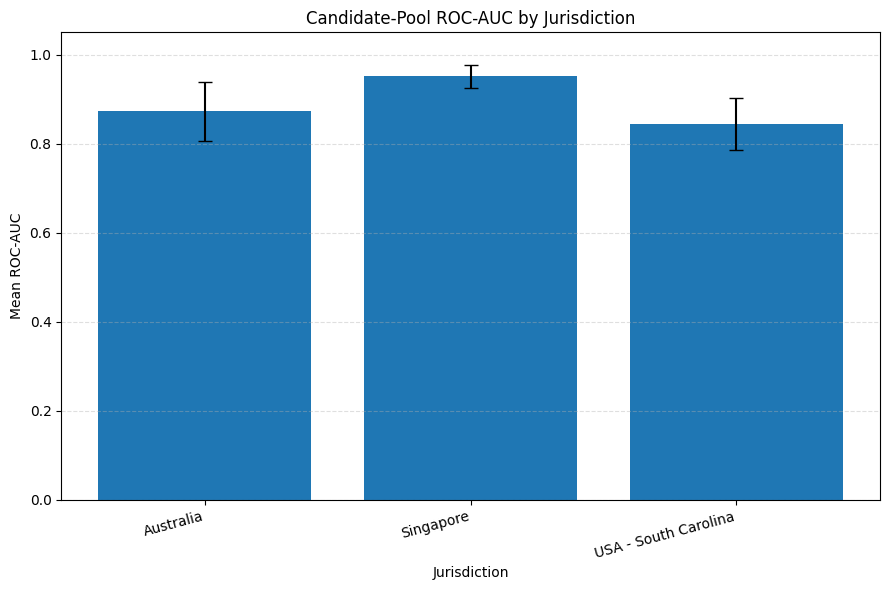

In [ ]:
# Replace roc_auc_df with your actual dataframe name.
roc_plot_df = roc_by_jurisdiction.copy()

roc_summary = roc_by_jurisdiction

plt.figure(figsize=(9, 6))

plt.bar(
    roc_summary["jurisdiction"],
    roc_summary["mean"],
    yerr=roc_summary["std"].fillna(0),
    capsize=5
)

plt.title("Candidate-Pool ROC-AUC by Jurisdiction")
plt.xlabel("Jurisdiction")
plt.ylabel("Mean ROC-AUC")
plt.ylim(0, 1.05)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.savefig("roc_auc_by_jurisdiction.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# Example timing helper. Wrap the actual function calls in your pipeline.

def benchmark_function(func, *args, repeats=5, **kwargs):
    timings_ms = []

    for _ in range(repeats):
        start = time.perf_counter()
        func(*args, **kwargs)
        timings_ms.append((time.perf_counter() - start) * 1000)

    return {
        "mean_ms": float(np.mean(timings_ms)),
        "median_ms": float(np.median(timings_ms)),
        "std_ms": float(np.std(timings_ms)),
        "min_ms": float(np.min(timings_ms)),
        "max_ms": float(np.max(timings_ms))
    }


# Example using the already cached results:
efficiency_rows = []

for query_id, entry in retrieval_cache.items():
    result = benchmark_function(get_rankings, entry, 0.7, repeats=10)

    efficiency_rows.append({
        "query_id": query_id,
        **result
    })

efficiency_df = pd.DataFrame(efficiency_rows)

display(efficiency_df.describe())

efficiency_df.to_csv(
    f"{OUTPUT_DIR}/cached_ranking_efficiency.csv", index=False
)

,mean_ms,median_ms,std_ms,min_ms,max_ms
count,90.000000,90.000000,90.000000,90.000000,90.000000
mean,0.063666,0.051960,0.031701,0.046301,0.151375
std,0.043217,0.020905,0.092931,0.019428,0.319063
min,0.026524,0.024405,0.005219,0.023530,0.041740
25%,0.040950,0.035039,0.009934,0.027860,0.070793
50%,0.051651,0.046073,0.012987,0.040405,0.086130
75%,0.071631,0.065373,0.016880,0.059930,0.111072
max,0.311977,0.103970,0.671753,0.087580,2.326339


['query_id', 'mean_ms', 'median_ms', 'std_ms', 'min_ms', 'max_ms']


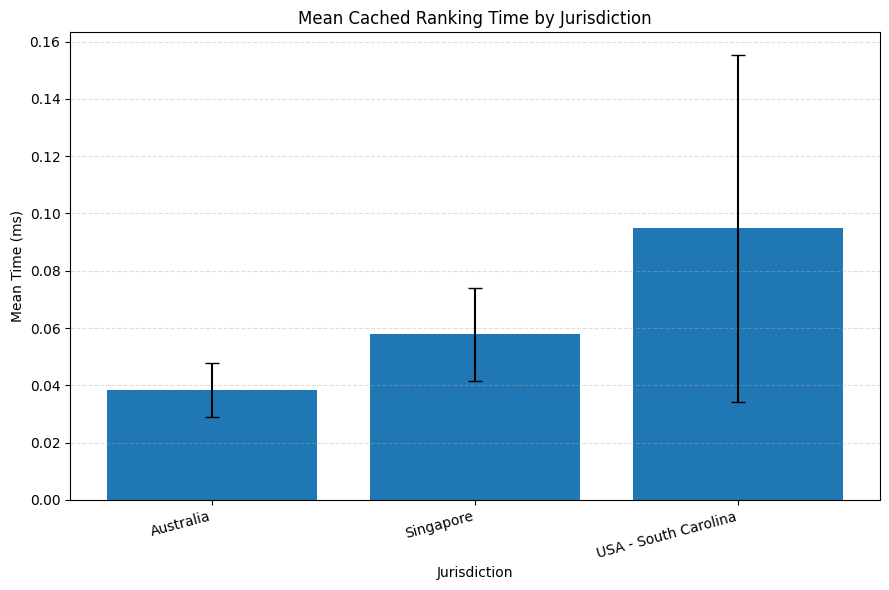

In [ ]:
# Check columns first
print(efficiency_df.columns.tolist())

# Add jurisdiction using the model-assisted reference
if "jurisdiction" not in efficiency_df.columns:
    efficiency_df["jurisdiction"] = efficiency_df["query_id"].map(
        lambda qid: reference[qid]["jurisdiction"]
        if qid in reference else "Unknown"
    )

efficiency_summary = (
    efficiency_df.groupby("jurisdiction")["mean_ms"]
    .agg(["mean", "std"])
    .reset_index()
)

plt.figure(figsize=(9, 6))
plt.bar(
    efficiency_summary["jurisdiction"],
    efficiency_summary["mean"],
    yerr=efficiency_summary["std"].fillna(0),
    capsize=5
)

plt.title("Mean Cached Ranking Time by Jurisdiction")
plt.xlabel("Jurisdiction")
plt.ylabel("Mean Time (ms)")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.savefig("cached_ranking_efficiency.png", dpi=300, bbox_inches="tight")
plt.show()

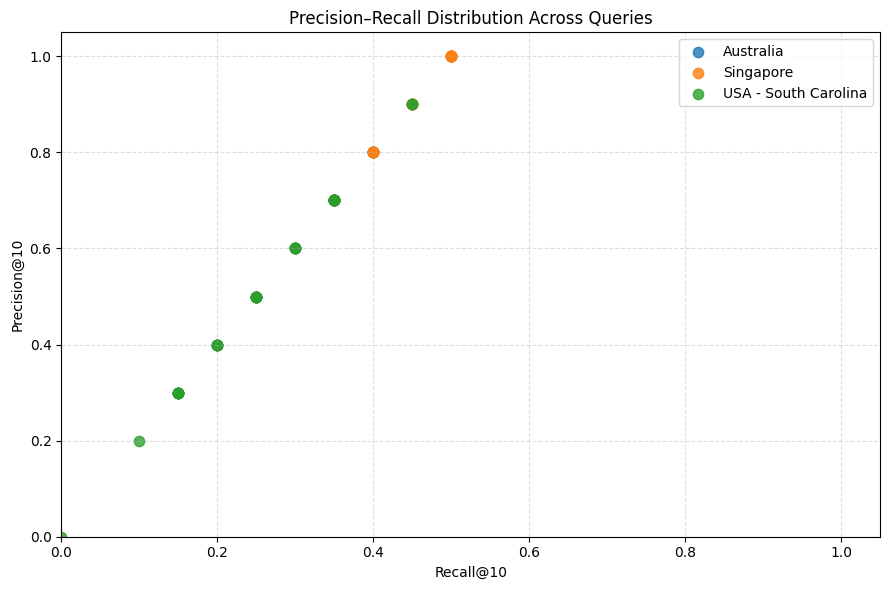

In [ ]:
plt.figure(figsize=(9, 6))

for jurisdiction, group in query_plot_df.groupby("jurisdiction"):
    plt.scatter(
        group["Recall"],
        group["Precision"],
        label=jurisdiction,
        alpha=0.8,
        s=55
    )

plt.title("Precision–Recall Distribution Across Queries")
plt.xlabel("Recall@10")
plt.ylabel("Precision@10")
plt.xlim(0, 1.05)
plt.ylim(0, 1.05)
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend()
plt.tight_layout()
plt.savefig("precision_recall_scatter.png", dpi=300, bbox_inches="tight")
plt.show()

TABLE 1 — RRF EXPERIMENT


,k,P@20,R@20,F1@20,MRR,nDCG@20
0,10,0.5344,0.5344,0.5344,0.9157,0.5614
1,20,0.5339,0.5339,0.5339,0.9333,0.5608
2,30,0.5272,0.5272,0.5272,0.9417,0.5545
3,40,0.5222,0.5222,0.5222,0.9472,0.5498
4,60,0.5183,0.5183,0.5183,0.9472,0.5465
5,80,0.5139,0.5139,0.5139,0.9528,0.5427
6,100,0.5133,0.5133,0.5133,0.9528,0.5415


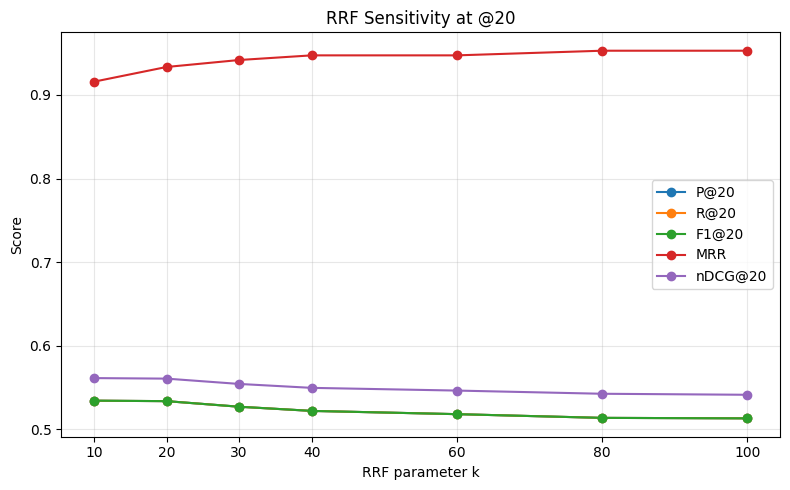

TABLE 2 — BETA SENSITIVITY


,β,R@20,MRR,nDCG@20
0,0.0,0.5600,0.9312,0.5654
1,0.1,0.5600,0.9312,0.5666
2,0.2,0.5600,0.9256,0.5673
3,0.3,0.5606,0.9255,0.5675
4,0.4,0.5617,0.9265,0.5675
5,0.5,0.5589,0.9172,0.5646
6,0.6,0.5589,0.9153,0.5628
7,0.7,0.5544,0.9098,0.5599
8,0.8,0.5461,0.9088,0.5547
9,0.9,0.5400,0.8888,0.5488


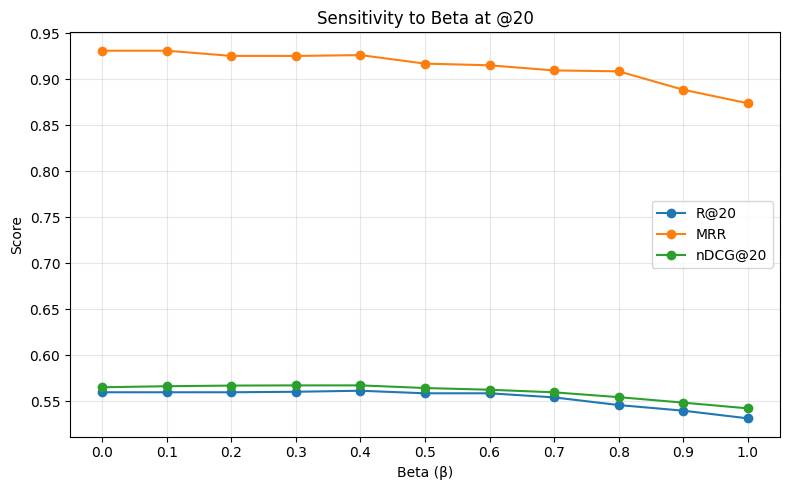

TABLE 3 — ABLATION STUDY


,Configuration,MRR,nDCG@20
0,Semantic only,0.8877,0.4813
1,Lexical only,0.7678,0.4164
2,Hybrid (α=0.5),0.9119,0.5552
3,Hybrid (α=0.7),0.9312,0.5654


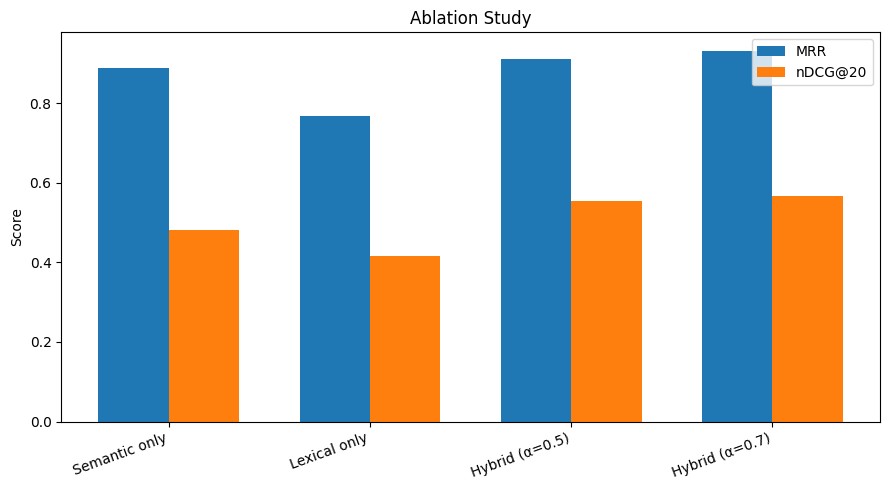

TABLE 4 — GAMMA SENSITIVITY


,γ,R@20,MRR,nDCG@20
0,0.0,0.5617,0.9265,0.5675
1,0.1,0.5611,0.9255,0.5672
2,0.2,0.5611,0.9255,0.5670
3,0.3,0.5606,0.9255,0.5672
4,0.4,0.5600,0.9256,0.5671
5,0.5,0.5600,0.9256,0.5673
6,0.6,0.5600,0.9257,0.5668
7,0.7,0.5606,0.9312,0.5672
8,0.8,0.5589,0.9312,0.5657
9,0.9,0.5600,0.9312,0.5661


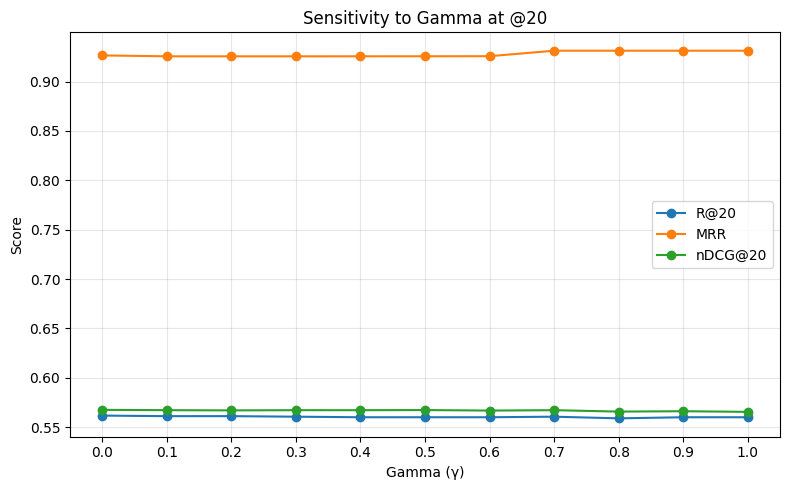

TABLE 5 — FINAL SYSTEM COMPARISON


,Configuration,R@20,MRR,nDCG@20
0,Semantic only,0.4750,0.8877,0.4813
1,Lexical only,0.4000,0.7678,0.4164
2,Hybrid (α=0.5),0.5278,0.9119,0.5552
3,Hybrid (α=0.7),0.5600,0.9312,0.5654
4,Hybrid + Citation (β=0.2),0.5600,0.9312,0.5654
5,"Full System (α=.7, β=.2, γ=.9)",0.5600,0.9312,0.5661


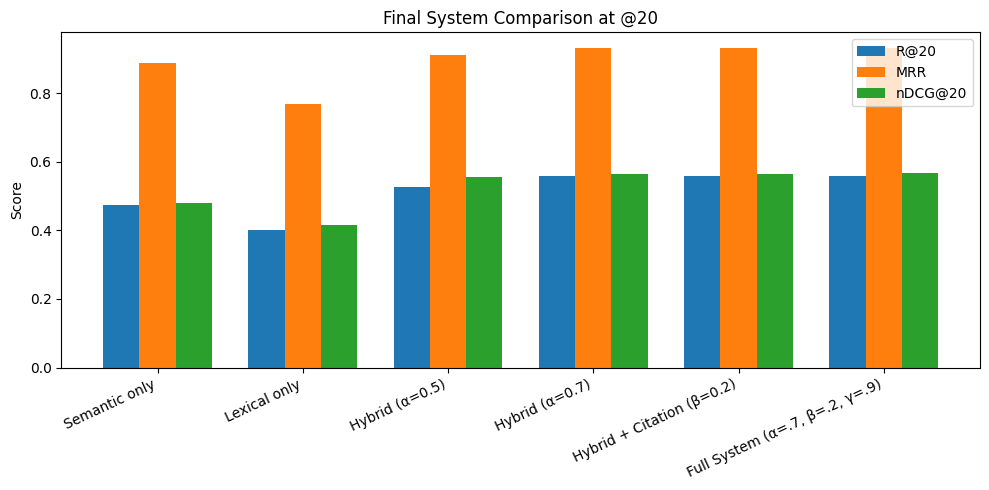

TABLE 6 — JURISDICTION-WISE RESULTS


,Jurisdiction,TP,FP,FN,Precision,Recall,F1
0,Australia,10.7667,9.2333,9.2333,0.5383,0.5383,0.5383
1,Singapore,14.2667,5.7333,5.7333,0.7133,0.7133,0.7133
2,USA - South Carolina,8.5667,11.4333,11.4333,0.4283,0.4283,0.4283


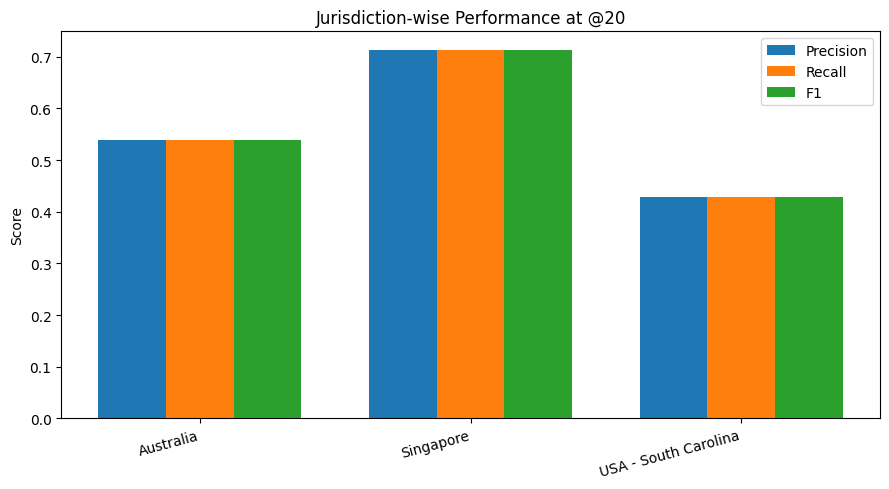

All tables and plots saved in: /content/drive/MyDrive/legal_rag/evaluation
Excel workbook: /content/drive/MyDrive/legal_rag/evaluation/legaltalk_tables_at20.xlsx


In [ ]:
# ============================================================
# LEGALTALK EVALUATION — UPDATED TO @20
# Preserves the column structure of the six Word tables.
# Generates updated tables and plots.
# ============================================================

import os
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Save outputs in the existing evaluation directory
EVAL_DIR = "/content/drive/MyDrive/legal_rag/evaluation"
os.makedirs(EVAL_DIR, exist_ok=True)

K = 20
PARAM_VALUES = np.round(np.arange(0.0, 1.01, 0.1), 1)


# ============================================================
# 1. METRIC FUNCTIONS
# Binary relevance: a case is relevant if it is in relevant_cases.
# Graded relevance: use graded_relevance for nDCG.
# ============================================================

def metrics_at20(ranking, relevant, graded=None):
    ranking = [str(x) for x in ranking]
    relevant = set(str(x) for x in relevant)
    graded = {
        str(k): float(v) for k, v in (graded or {}).items()
    }

    top20 = ranking[:20]
    retrieved = set(top20)

    tp = len(retrieved & relevant)
    fp = len(retrieved - relevant)
    fn = len(relevant - retrieved)

    precision = tp / len(top20) if top20 else 0.0
    recall = tp / len(relevant) if relevant else 0.0

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0.0
    )

    reciprocal_rank = 0.0
    for rank, case_id in enumerate(ranking, start=1):
        if case_id in relevant:
            reciprocal_rank = 1.0 / rank
            break

    # Binary nDCG@20
    binary_gains = [
        1 if case_id in relevant else 0
        for case_id in top20
    ]

    dcg_binary = sum(
        gain / np.log2(rank + 1)
        for rank, gain in enumerate(binary_gains, start=1)
    )

    ideal_binary_hits = min(len(relevant), 20)

    idcg_binary = sum(
        1 / np.log2(rank + 1)
        for rank in range(1, ideal_binary_hits + 1)
    )

    ndcg_binary = (
        dcg_binary / idcg_binary if idcg_binary else 0.0
    )

    # Graded nDCG@20
    if graded:
        graded_gains = [
            (2 ** graded.get(case_id, 0) - 1)
            / np.log2(rank + 1)
            for rank, case_id in enumerate(top20, start=1)
        ]

        dcg_graded = sum(graded_gains)

        ideal_relevances = sorted(
            graded.values(), reverse=True
        )[:20]

        idcg_graded = sum(
            (2 ** rel - 1) / np.log2(rank + 1)
            for rank, rel in enumerate(ideal_relevances, start=1)
        )

        ndcg = (
            dcg_graded / idcg_graded if idcg_graded else 0.0
        )
    else:
        ndcg = ndcg_binary

    return {
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "P@20": precision,
        "R@20": recall,
        "F1@20": f1,
        "MRR": reciprocal_rank,
        "nDCG@20": ndcg
    }


def evaluate_all_queries(ranking_function):
    results = []

    for query_id, ref in reference.items():
        if query_id not in retrieval_cache:
            continue

        ranking = ranking_function(query_id, ref)
        metrics = metrics_at20(
            ranking,
            ref["relevant_cases"],
            ref.get("graded_relevance", {})
        )

        results.append({
            "query_id": query_id,
            "jurisdiction": ref.get("jurisdiction", "Unknown"),
            **metrics
        })

    return pd.DataFrame(results)


def plot_lines(df, x, ys, xlabel, title, filename):
    plt.figure(figsize=(8, 5))

    for y in ys:
        plt.plot(df[x], df[y], marker="o", label=y)

    plt.xlabel(xlabel)
    plt.ylabel("Score")
    plt.title(title)
    plt.xticks(df[x])
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(
        os.path.join(EVAL_DIR, filename),
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()


# ============================================================
# TABLE 1 — RRF EXPERIMENT
# Exact columns:
# k | P@20 | R@20 | F1@20 | MRR | nDCG@20
# ============================================================

def rrf_ranking(entry, rrf_k=60):
    dense = entry["dense"]
    bm25 = entry["bm25"]

    dense_order = sorted(
        dense, key=dense.get, reverse=True
    )
    bm25_order = sorted(
        bm25, key=bm25.get, reverse=True
    )

    dense_rank = {
        case_id: rank
        for rank, case_id in enumerate(dense_order, start=1)
    }
    bm25_rank = {
        case_id: rank
        for rank, case_id in enumerate(bm25_order, start=1)
    }

    candidates = set(dense_rank) | set(bm25_rank)

    scores = {}
    for case_id in candidates:
        scores[case_id] = (
            1.0 / (rrf_k + dense_rank[case_id])
            if case_id in dense_rank else 0.0
        ) + (
            1.0 / (rrf_k + bm25_rank[case_id])
            if case_id in bm25_rank else 0.0
        )

    return sorted(candidates, key=scores.get, reverse=True)


rrf_k_values = [10, 20, 30, 40, 60, 80, 100]
rrf_rows = []

for rrf_k in rrf_k_values:
    df = evaluate_all_queries(
        lambda qid, ref, kk=rrf_k:
            rrf_ranking(retrieval_cache[qid], rrf_k=kk)
    )

    rrf_rows.append({
        "k": rrf_k,
        "P@20": df["P@20"].mean(),
        "R@20": df["R@20"].mean(),
        "F1@20": df["F1@20"].mean(),
        "MRR": df["MRR"].mean(),
        "nDCG@20": df["nDCG@20"].mean()
    })

rrf_table = pd.DataFrame(rrf_rows)

print("TABLE 1 — RRF EXPERIMENT")
display(rrf_table.round(4))

plot_lines(
    rrf_table,
    "k",
    ["P@20", "R@20", "F1@20", "MRR", "nDCG@20"],
    "RRF parameter k",
    "RRF Sensitivity at @20",
    "rrf_sensitivity_at20.png"
)


# ============================================================
# TABLE 2 — BETA SENSITIVITY
# Exact columns:
# β | R@20 | MRR | nDCG@20
# ============================================================

beta_rows = []

for beta in PARAM_VALUES:
    df = evaluate_all_queries(
        lambda qid, ref, b=float(beta):
            get_influence_ranking(
                retrieval_cache[qid],
                alpha=0.7,
                beta=b
            )
    )

    beta_rows.append({
        "β": beta,
        "R@20": df["R@20"].mean(),
        "MRR": df["MRR"].mean(),
        "nDCG@20": df["nDCG@20"].mean()
    })

beta_table = pd.DataFrame(beta_rows)

print("TABLE 2 — BETA SENSITIVITY")
display(beta_table.round(4))

plot_lines(
    beta_table,
    "β",
    ["R@20", "MRR", "nDCG@20"],
    "Beta (β)",
    "Sensitivity to Beta at @20",
    "beta_sensitivity_at20.png"
)


# ============================================================
# TABLE 3 — ABLATION STUDY
# Exact columns:
# Configuration | MRR | nDCG@20
# ============================================================

ablation_configs = [
    ("Semantic only", 1.0),
    ("Lexical only", 0.0),
    ("Hybrid (α=0.5)", 0.5),
    ("Hybrid (α=0.7)", 0.7)
]

ablation_rows = []

for name, alpha in ablation_configs:
    df = evaluate_all_queries(
        lambda qid, ref, a=alpha:
            get_rankings(retrieval_cache[qid], a)
    )

    ablation_rows.append({
        "Configuration": name,
        "MRR": df["MRR"].mean(),
        "nDCG@20": df["nDCG@20"].mean()
    })

ablation_table = pd.DataFrame(ablation_rows)

print("TABLE 3 — ABLATION STUDY")
display(ablation_table.round(4))

plt.figure(figsize=(9, 5))
x = np.arange(len(ablation_table))
width = 0.35

plt.bar(
    x - width / 2,
    ablation_table["MRR"],
    width,
    label="MRR"
)
plt.bar(
    x + width / 2,
    ablation_table["nDCG@20"],
    width,
    label="nDCG@20"
)

plt.xticks(
    x,
    ablation_table["Configuration"],
    rotation=20,
    ha="right"
)
plt.ylabel("Score")
plt.title("Ablation Study")
plt.legend()
plt.tight_layout()
plt.savefig(
    os.path.join(EVAL_DIR, "ablation_at20.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# ============================================================
# TABLE 4 — GAMMA SENSITIVITY
# Exact columns:
# γ | R@20 | MRR | nDCG@20
# ============================================================

gamma_rows = []

for gamma in PARAM_VALUES:
    df = evaluate_all_queries(
        lambda qid, ref, g=float(gamma):
            get_final_ranking(
                retrieval_cache[qid],
                alpha=0.7,
                beta=0.2,
                gamma=g
            )
    )

    gamma_rows.append({
        "γ": gamma,
        "R@20": df["R@20"].mean(),
        "MRR": df["MRR"].mean(),
        "nDCG@20": df["nDCG@20"].mean()
    })

gamma_table = pd.DataFrame(gamma_rows)

print("TABLE 4 — GAMMA SENSITIVITY")
display(gamma_table.round(4))

plot_lines(
    gamma_table,
    "γ",
    ["R@20", "MRR", "nDCG@20"],
    "Gamma (γ)",
    "Sensitivity to Gamma at @20",
    "gamma_sensitivity_at20.png"
)


# ============================================================
# TABLE 5 — FINAL SYSTEM COMPARISON
# Exact columns:
# Configuration | R@20 | MRR | nDCG@20
# ============================================================

final_configs = [
    ("Semantic only", 1.0, 0.0, 1.0),
    ("Lexical only", 0.0, 0.0, 1.0),
    ("Hybrid (α=0.5)", 0.5, 0.0, 1.0),
    ("Hybrid (α=0.7)", 0.7, 0.0, 1.0),
    ("Hybrid + Citation (β=0.2)", 0.7, 0.2, 1.0),
    ("Full System (α=.7, β=.2, γ=.9)", 0.7, 0.2, 0.9)
]

final_rows = []

for name, alpha, beta, gamma in final_configs:
    df = evaluate_all_queries(
        lambda qid, ref, a=alpha, b=beta, g=gamma:
            get_final_ranking(
                retrieval_cache[qid],
                alpha=a,
                beta=b,
                gamma=g
            )
    )

    final_rows.append({
        "Configuration": name,
        "R@20": df["R@20"].mean(),
        "MRR": df["MRR"].mean(),
        "nDCG@20": df["nDCG@20"].mean()
    })

final_comparison = pd.DataFrame(final_rows)

print("TABLE 5 — FINAL SYSTEM COMPARISON")
display(final_comparison.round(4))

plt.figure(figsize=(10, 5))
x = np.arange(len(final_comparison))
width = 0.25

for offset, metric in zip(
    [-width, 0, width],
    ["R@20", "MRR", "nDCG@20"]
):
    plt.bar(
        x + offset,
        final_comparison[metric],
        width,
        label=metric
    )

plt.xticks(
    x,
    final_comparison["Configuration"],
    rotation=25,
    ha="right"
)
plt.ylabel("Score")
plt.title("Final System Comparison at @20")
plt.legend()
plt.tight_layout()
plt.savefig(
    os.path.join(EVAL_DIR, "final_system_at20.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# ============================================================
# TABLE 6 — JURISDICTION-WISE BINARY RELEVANCE
# Exact columns:
# Jurisdiction | TP | FP | FN | Precision | Recall | F1
# Calculated at top 20.
# ============================================================

jurisdiction_rows = []

for jurisdiction in sorted({
    ref.get("jurisdiction", "Unknown")
    for ref in reference.values()
}):
    subset_rows = []

    for query_id, ref in reference.items():
        if query_id not in retrieval_cache:
            continue

        if ref.get("jurisdiction", "Unknown") != jurisdiction:
            continue

        ranking = get_final_ranking(
            retrieval_cache[query_id],
            alpha=0.7,
            beta=0.2,
            gamma=0.9
        )

        subset_rows.append(
            metrics_at20(
                ranking,
                ref["relevant_cases"],
                ref.get("graded_relevance", {})
            )
        )

    df = pd.DataFrame(subset_rows)

    if df.empty:
        continue

    jurisdiction_rows.append({
        "Jurisdiction": jurisdiction,
        "TP": df["TP"].mean(),
        "FP": df["FP"].mean(),
        "FN": df["FN"].mean(),
        "Precision": df["P@20"].mean(),
        "Recall": df["R@20"].mean(),
        "F1": df["F1@20"].mean()
    })

jurisdiction_table = pd.DataFrame(jurisdiction_rows)

print("TABLE 6 — JURISDICTION-WISE RESULTS")
display(jurisdiction_table.round(4))

plt.figure(figsize=(9, 5))
x = np.arange(len(jurisdiction_table))
width = 0.25

for offset, metric in zip(
    [-width, 0, width],
    ["Precision", "Recall", "F1"]
):
    plt.bar(
        x + offset,
        jurisdiction_table[metric],
        width,
        label=metric
    )

plt.xticks(
    x,
    jurisdiction_table["Jurisdiction"],
    rotation=15,
    ha="right"
)
plt.ylabel("Score")
plt.title("Jurisdiction-wise Performance at @20")
plt.legend()
plt.tight_layout()
plt.savefig(
    os.path.join(EVAL_DIR, "jurisdiction_results_at20.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# ============================================================
# SAVE TABLES TO ONE EXCEL FILE
# ============================================================

excel_path = os.path.join(EVAL_DIR, "legaltalk_tables_at20.xlsx")

with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    rrf_table.to_excel(writer, sheet_name="RRF", index=False)
    beta_table.to_excel(writer, sheet_name="Beta Sensitivity", index=False)
    ablation_table.to_excel(writer, sheet_name="Ablation", index=False)
    gamma_table.to_excel(writer, sheet_name="Gamma Sensitivity", index=False)
    final_comparison.to_excel(writer, sheet_name="Final System", index=False)
    jurisdiction_table.to_excel(writer, sheet_name="Jurisdiction", index=False)

print("All tables and plots saved in:", EVAL_DIR)
print("Excel workbook:", excel_path)